Dataset: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

> Mount google drive to load data

In [224]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


> Basic loading of packages. From Machine Learning 1 course.

In [225]:
#Base imports from ML1 course DSC445

import sys
import csv
import math
import numpy as np
import pandas as pd
import seaborn as sns
from operator import itemgetter
import time

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import joblib
from sklearn.feature_selection import RFE, VarianceThreshold, SelectFromModel
from sklearn.feature_selection import SelectKBest, mutual_info_regression, mutual_info_classif, chi2
from sklearn import metrics, linear_model
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.preprocessing import KBinsDiscretizer, scale, StandardScaler, OneHotEncoder

from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestCentroid
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import RadiusNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.semi_supervised import LabelPropagation
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import balanced_accuracy_score

import matplotlib.pyplot as plt

#Handle annoying warnings
import warnings, sklearn.exceptions
warnings.filterwarnings("ignore", category=sklearn.exceptions.ConvergenceWarning)

> Loading of data

In [226]:
bean_data = pd.read_excel("/content/drive/MyDrive/DePaul/Capstone/Dry_Bean_Dataset.xlsx", sheet_name=0)

In [227]:
bean_data.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### EDA

> Beginning of EDA

In [228]:
bean_data.shape

(13611, 17)

13611 rows, 17 columns

In [229]:
bean_data["Class"].value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


In [230]:
bean_data["Class"].unique()

array(['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
      dtype=object)

Dermason: ~26.05%

Sira: ~19.37%

Seker: ~14.89%

Horoz: ~14.17%

Cali: ~11.98%

Barbunya: ~9.71%

Bombay: ~3.84%


Data is imbalanced. An equal distribution is ~14.29% or 1944/1945 observations of each class. Undersampling, SMOTE, and class_weights with stratifiedFolding are all possible options to help alleviate the imbalanced data. More importantly, accuracy may not be the best metric for comparing models.


In [231]:
bean_data.isnull().sum()

,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


No missing data

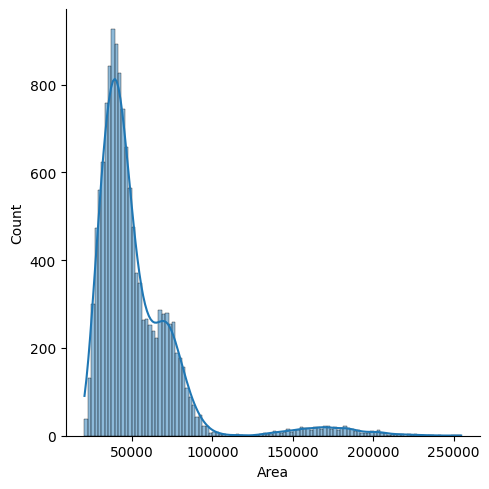

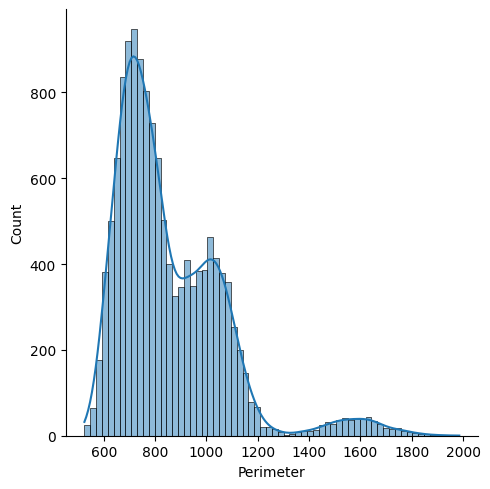

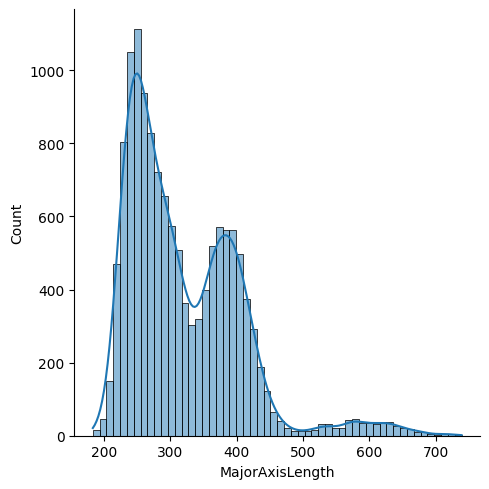

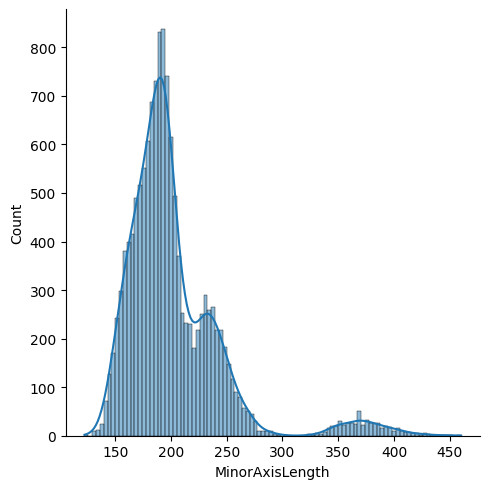

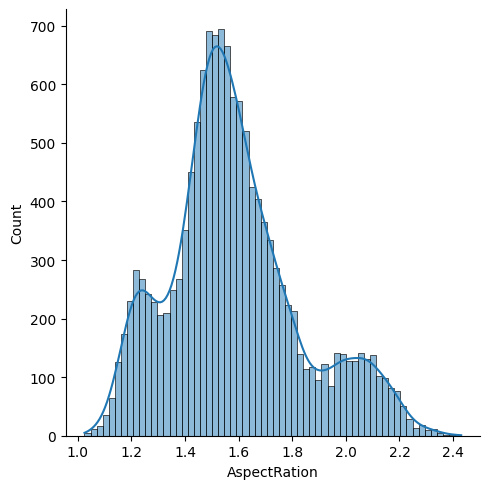

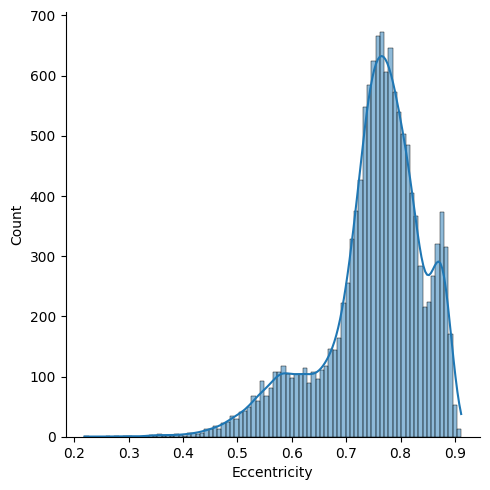

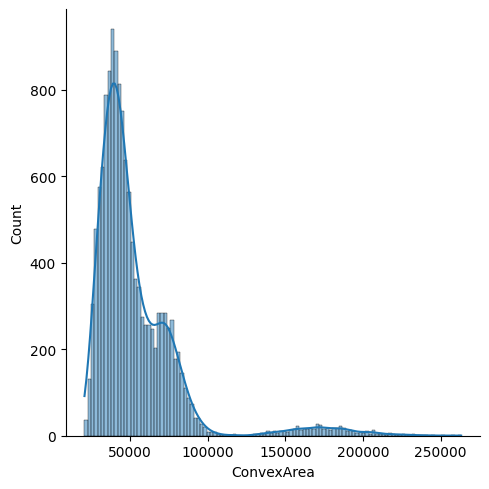

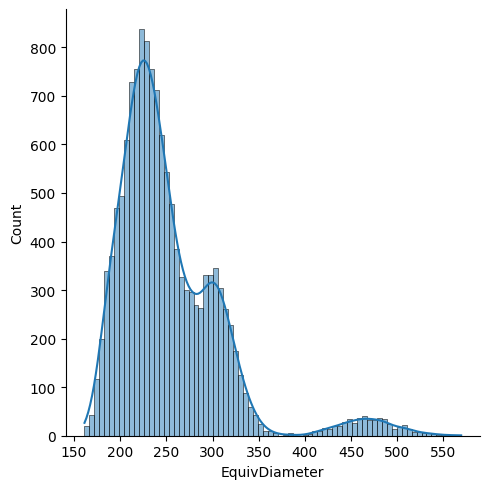

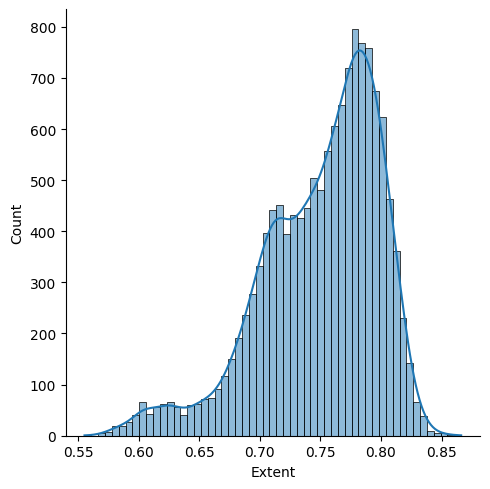

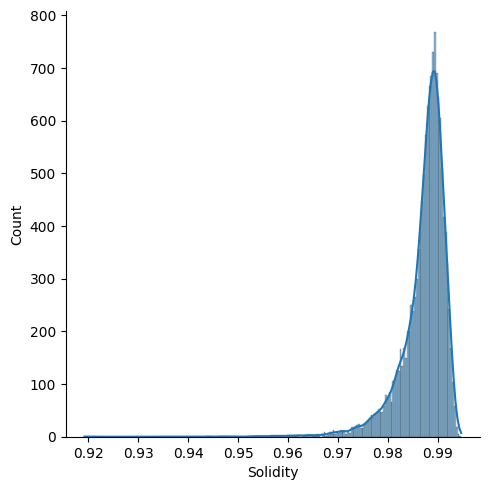

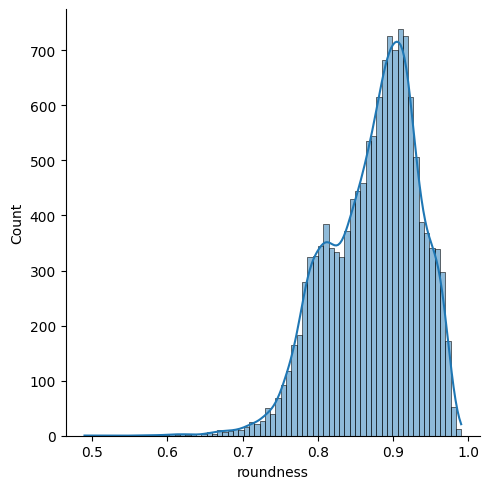

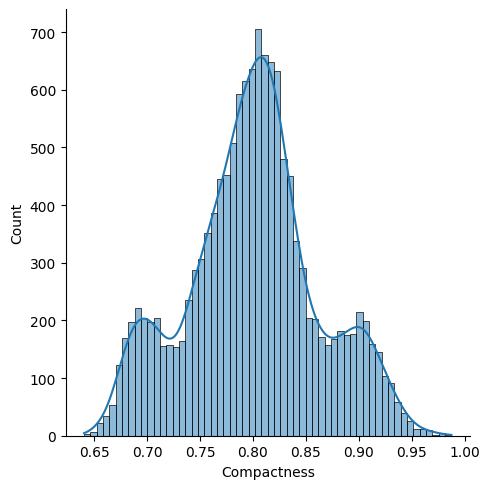

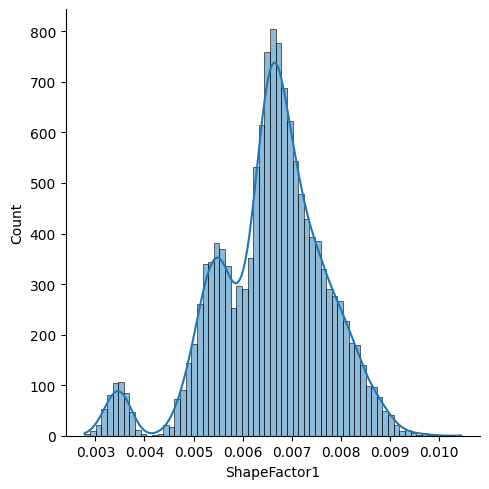

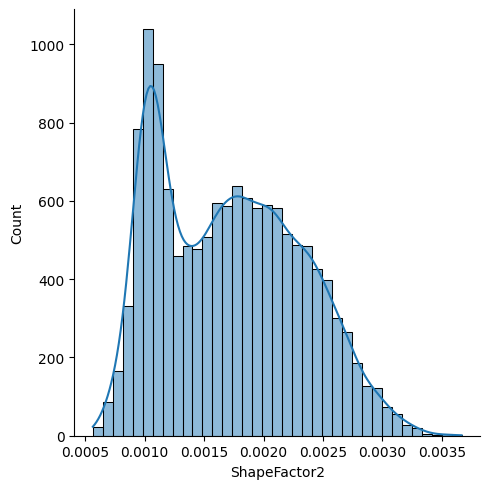

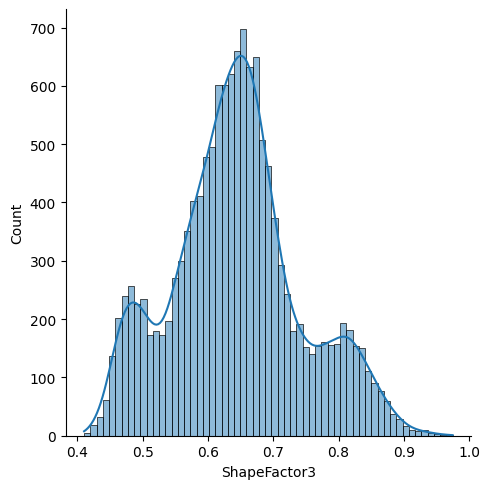

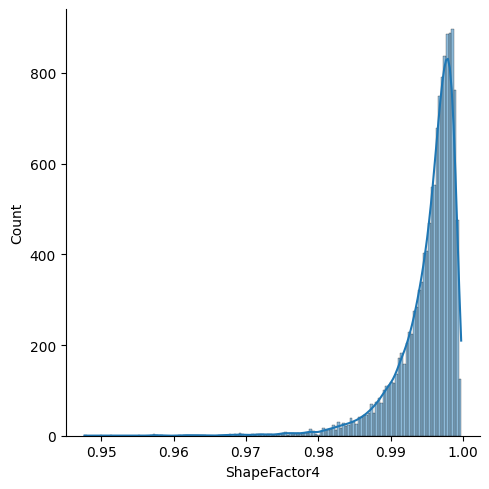

In [232]:
numerical_columns = bean_data.columns[:-1]

for column in numerical_columns:
  sns.displot(bean_data, x=column, kde=True)

Description of each distribution

Area: long right tail, high kurtosis

Perimeter: bimodal distribution with long right tail, high kurtosis

MajorAxisLength: bimodal distribution with right tail

MinorAxisLength: right tail, high kurtosis

AspectRation: high kurtosis, almost trimodal

Eccentricity: high kurtosis, long left tail

ConvexArea: high kurtosis, long right tail

EquivDiameter: nearly bimodal with right tial

Extent: Normal left skew

Solidity: high kurtosis, long left tail

roundness: long left tail

Compactness: high kurtosis, trimodal

ShapeFactor1: trimodal

ShapeFactor2: bimodal

ShapeFactor3: trimodal

ShapeFactor4: long left tail, high kurtosis

Most distributions show potential for log scaling.

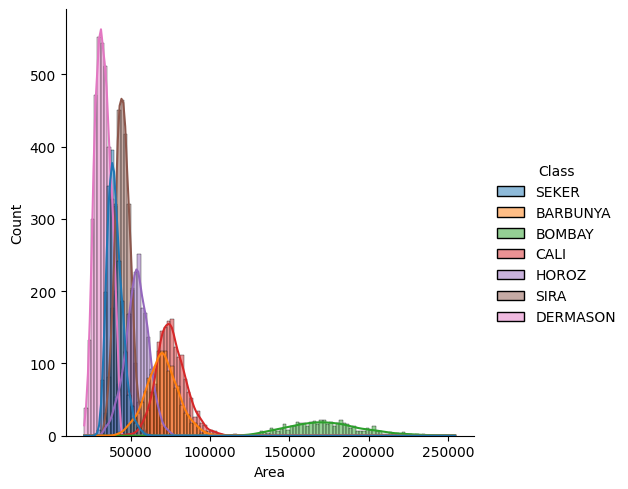

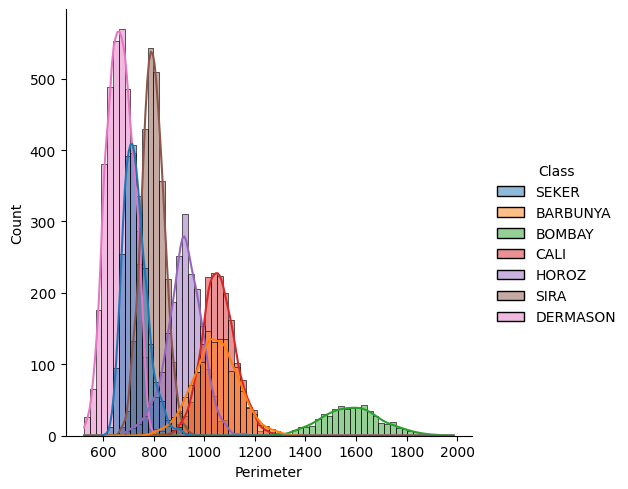

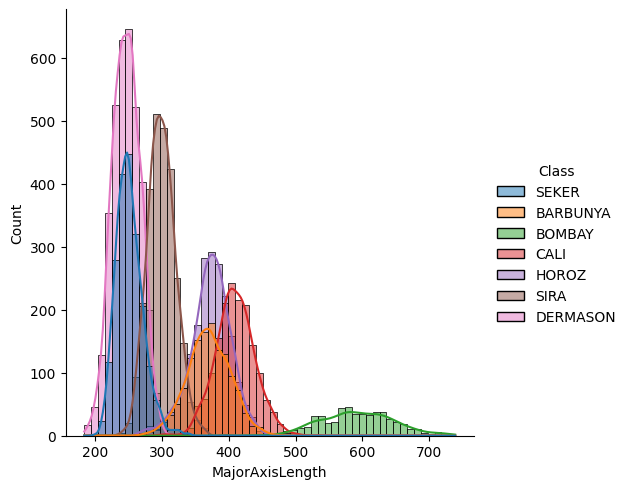

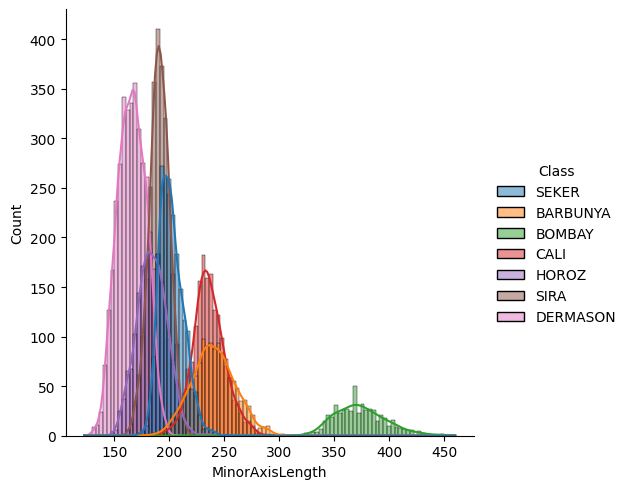

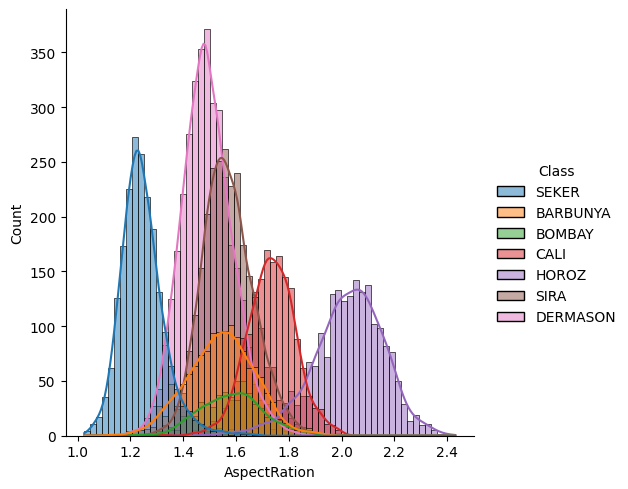

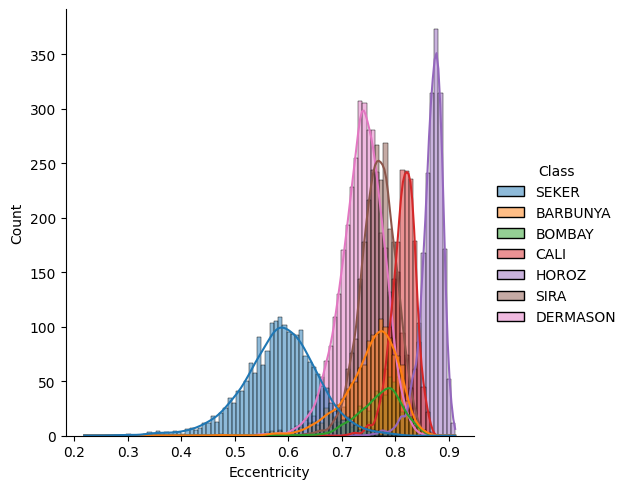

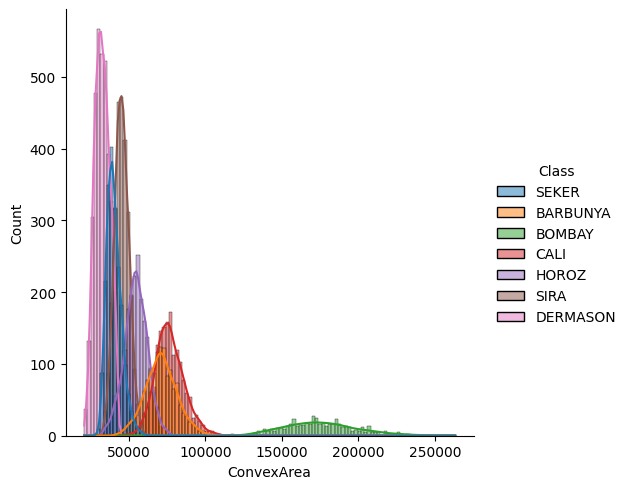

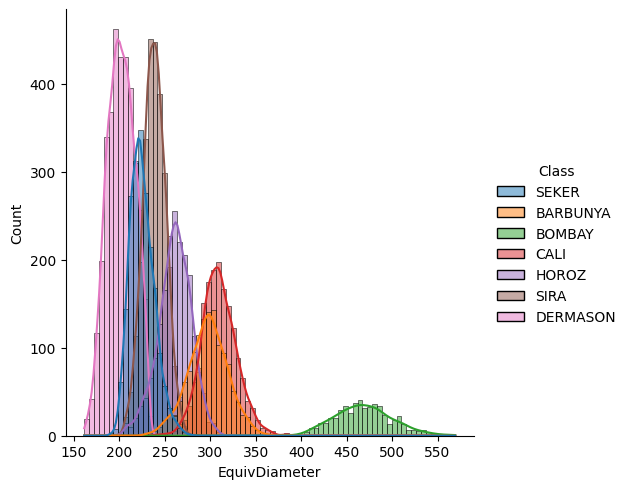

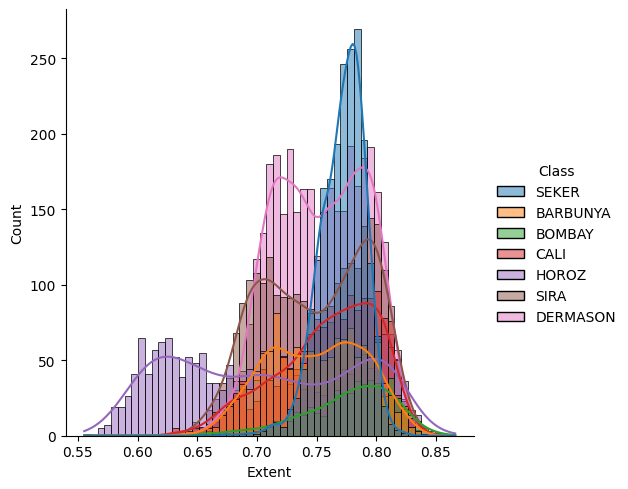

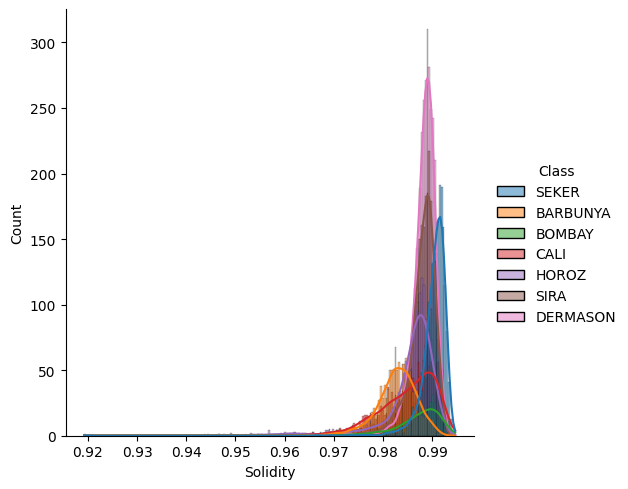

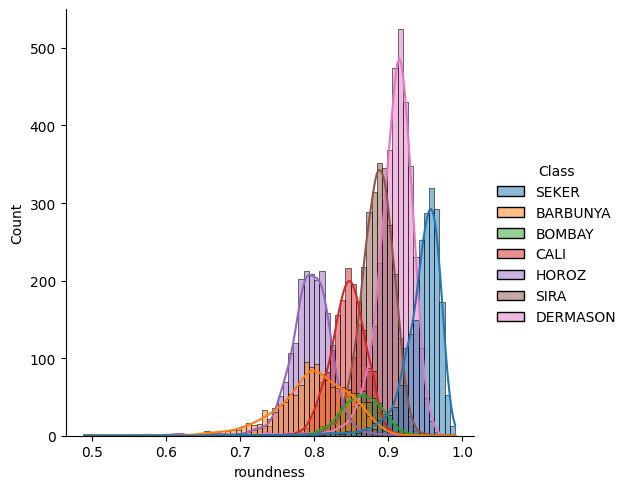

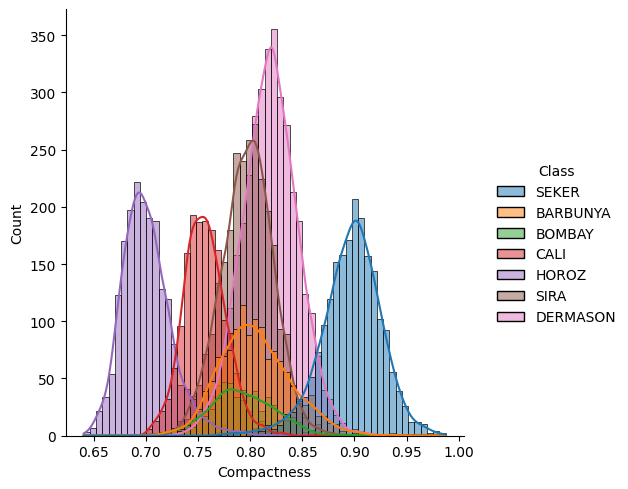

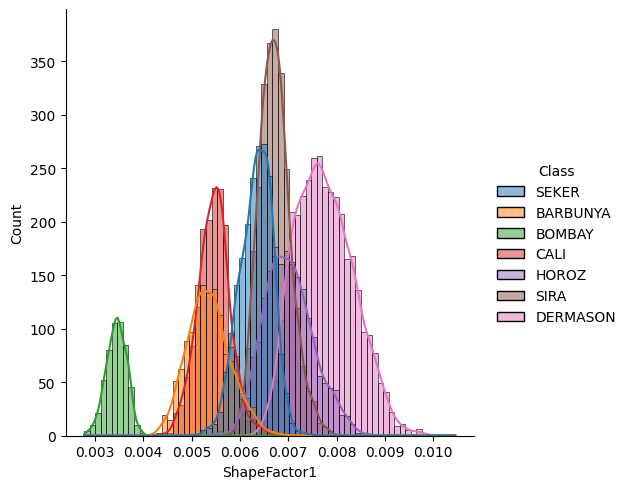

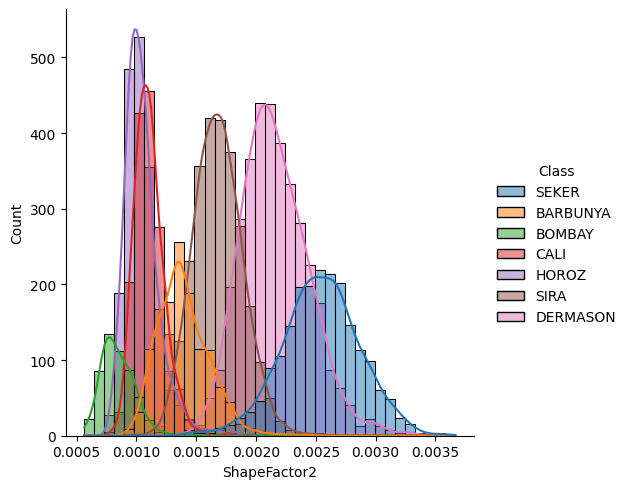

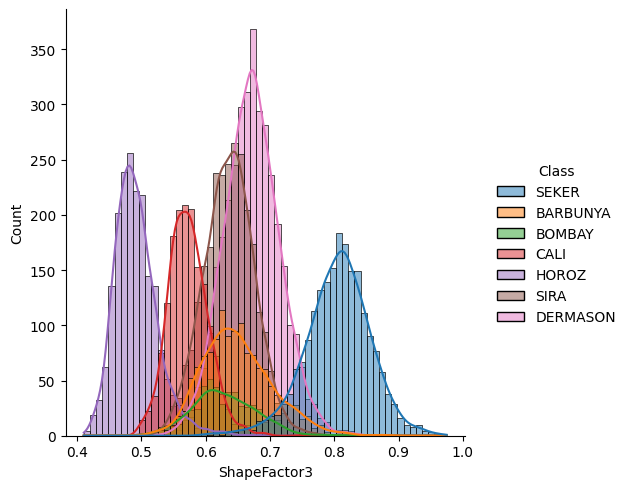

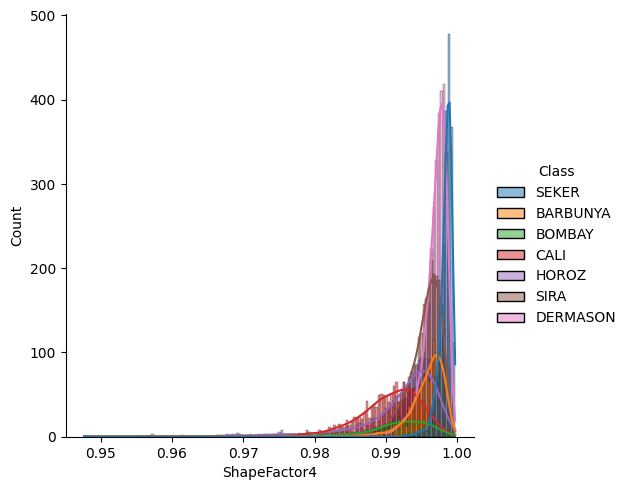

In [233]:
for column in numerical_columns:
  sns.displot(bean_data, x=column, hue="Class", kde=True)

Looking at the distributions by class, the multimodal nature of the overall distributions can be explained by class. BOMBAY shows unique distributions which causes the long tails in Area, Perimter, MajorAxisLength, MinorAxisLength,ConvexArea, and EquivDiameter.

In [234]:
features = bean_data.drop(columns=["Class"])
target = bean_data["Class"]

<Axes: >

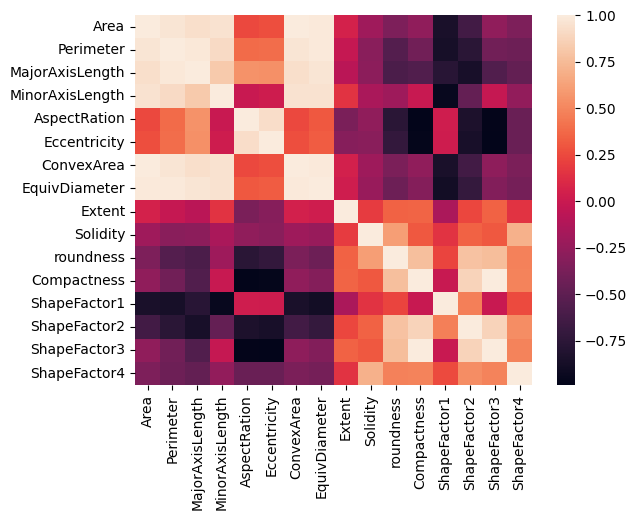

In [235]:
sns.heatmap(features.corr())

In [236]:
features.corr()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.966722,0.931834,0.951602,0.241735,0.267481,0.999939,0.984968,0.054345,-0.196585,-0.357530,-0.268067,-0.847958,-0.639291,-0.272145,-0.355721
Perimeter,0.966722,1.000000,0.977338,0.913179,0.385276,0.391066,0.967689,0.991380,-0.021160,-0.303970,-0.547647,-0.406857,-0.864623,-0.767592,-0.408435,-0.429310
MajorAxisLength,0.931834,0.977338,1.000000,0.826052,0.550335,0.541972,0.932607,0.961733,-0.078062,-0.284302,-0.596358,-0.568377,-0.773609,-0.859238,-0.568185,-0.482527
MinorAxisLength,0.951602,0.913179,0.826052,1.000000,-0.009161,0.019574,0.951339,0.948539,0.145957,-0.155831,-0.210344,-0.015066,-0.947204,-0.471347,-0.019326,-0.263749
AspectRation,0.241735,0.385276,0.550335,-0.009161,1.000000,0.924293,0.243301,0.303647,-0.370184,-0.267754,-0.766979,-0.987687,0.024593,-0.837841,-0.978592,-0.449264
Eccentricity,0.267481,0.391066,0.541972,0.019574,0.924293,1.000000,0.269255,0.318667,-0.319362,-0.297592,-0.722272,-0.970313,0.019920,-0.860141,-0.981058,-0.449354
ConvexArea,0.999939,0.967689,0.932607,0.951339,0.243301,0.269255,1.000000,0.985226,0.052564,-0.206191,-0.362083,-0.269922,-0.847950,-0.640862,-0.274024,-0.362049
EquivDiameter,0.984968,0.991380,0.961733,0.948539,0.303647,0.318667,0.985226,1.000000,0.028383,-0.231648,-0.435945,-0.327650,-0.892741,-0.713069,-0.330389,-0.392512
Extent,0.054345,-0.021160,-0.078062,0.145957,-0.370184,-0.319362,0.052564,0.028383,1.000000,0.191389,0.344411,0.354212,-0.141616,0.237956,0.347624,0.148502
Solidity,-0.196585,-0.303970,-0.284302,-0.155831,-0.267754,-0.297592,-0.206191,-0.231648,0.191389,1.000000,0.607150,0.303766,0.153388,0.343559,0.307662,0.702163


array([[<Axes: xlabel='Area', ylabel='Area'>,
        <Axes: xlabel='Perimeter', ylabel='Area'>,
        <Axes: xlabel='MajorAxisLength', ylabel='Area'>,
        <Axes: xlabel='MinorAxisLength', ylabel='Area'>,
        <Axes: xlabel='AspectRation', ylabel='Area'>,
        <Axes: xlabel='Eccentricity', ylabel='Area'>,
        <Axes: xlabel='ConvexArea', ylabel='Area'>,
        <Axes: xlabel='EquivDiameter', ylabel='Area'>,
        <Axes: xlabel='Extent', ylabel='Area'>,
        <Axes: xlabel='Solidity', ylabel='Area'>,
        <Axes: xlabel='roundness', ylabel='Area'>,
        <Axes: xlabel='Compactness', ylabel='Area'>,
        <Axes: xlabel='ShapeFactor1', ylabel='Area'>,
        <Axes: xlabel='ShapeFactor2', ylabel='Area'>,
        <Axes: xlabel='ShapeFactor3', ylabel='Area'>,
        <Axes: xlabel='ShapeFactor4', ylabel='Area'>],
       [<Axes: xlabel='Area', ylabel='Perimeter'>,
        <Axes: xlabel='Perimeter', ylabel='Perimeter'>,
        <Axes: xlabel='MajorAxisLength', ylabel=

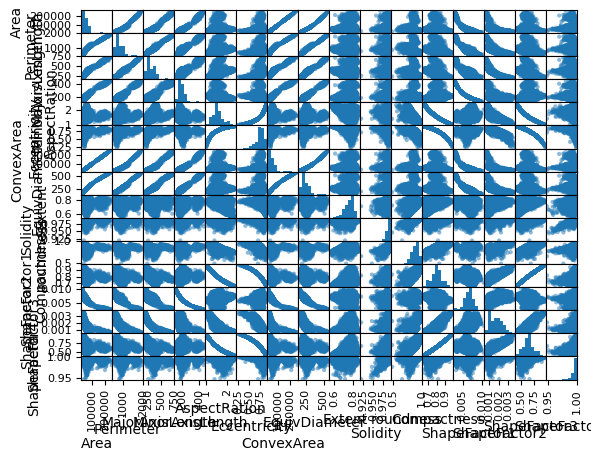

In [237]:
pd.plotting.scatter_matrix(bean_data)

A visual inspection shows similar plots across different unique combinations of variables.

<Axes: xlabel='AspectRation', ylabel='Eccentricity'>

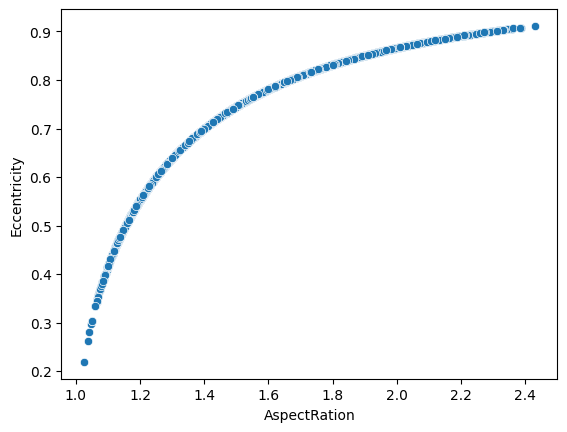

In [238]:
sns.scatterplot(data=bean_data, x="AspectRation", y="Eccentricity")

<Axes: xlabel='Area', ylabel='Perimeter'>

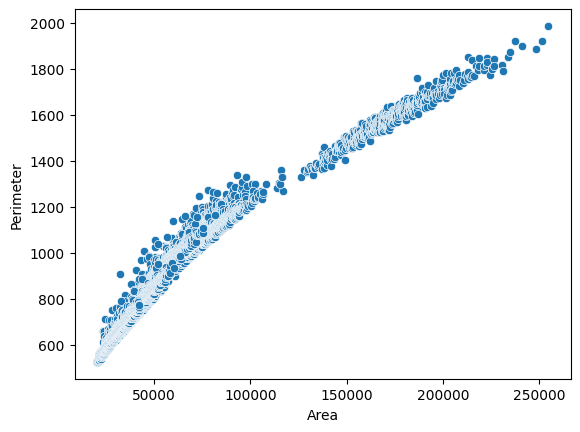

In [239]:
sns.scatterplot(data=bean_data, x="Area", y="Perimeter")

<Axes: xlabel='Area', ylabel='Eccentricity'>

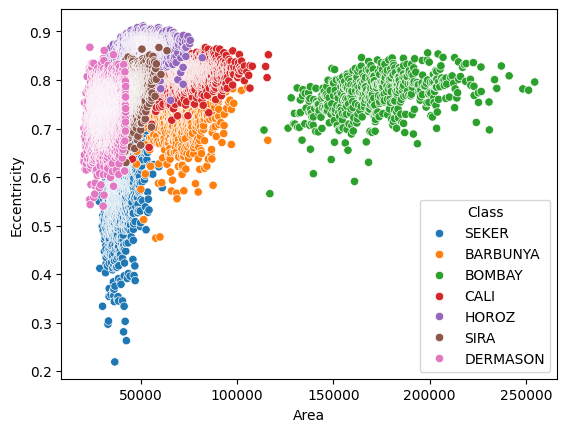

In [240]:
sns.scatterplot(data=bean_data, x="Area", y="Eccentricity", hue="Class")

<Axes: xlabel='AspectRation', ylabel='Eccentricity'>

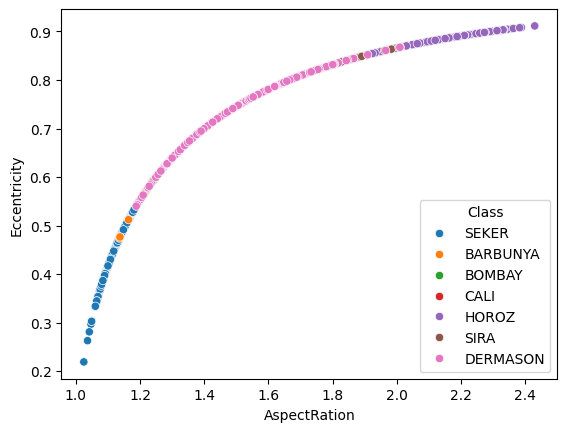

In [241]:
sns.scatterplot(data=bean_data, x="AspectRation", y="Eccentricity", hue="Class")

<Axes: xlabel='Solidity', ylabel='Eccentricity'>

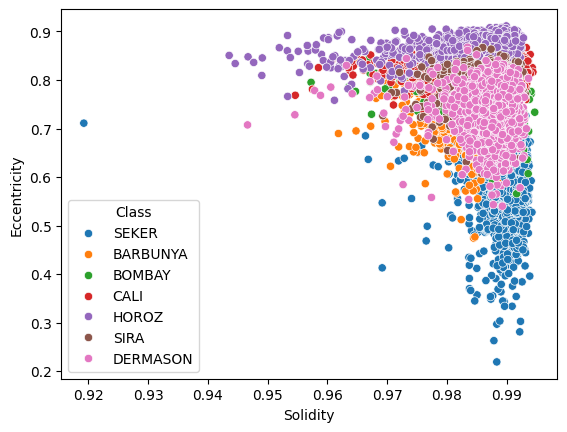

In [242]:
sns.scatterplot(data=bean_data, x="Solidity", y="Eccentricity", hue="Class")

There is heavy correlation across the features. This is expected as they are descriptions of the same object. PCA/LDA are approaches that help remedy this.

### Point biserial correlation and PCA/LDA testing

Testing point biserial correlation

In [243]:
biserial_data = pd.get_dummies(bean_data, columns=["Class"], drop_first=False)
barbunya_series = biserial_data["Class_BARBUNYA"].astype("float")
bombay_series = biserial_data["Class_BOMBAY"].astype("float")
cali_series = biserial_data["Class_CALI"].astype("float")
dermason_series = biserial_data["Class_DERMASON"].astype("float")
horoz_series = biserial_data["Class_HOROZ"].astype("float")
seker_series = biserial_data["Class_SEKER"].astype("float")
sira_series = biserial_data["Class_SIRA"].astype("float")

We are only looking to calculate the correlation coefficient. To test if it is significantly different from no correlation, both distributions have to be normal. Since there are 7 distributions, there is a lack of normalcy between the distributions because of the one versus many approach.

In [244]:
features.corrwith(barbunya_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,1.874197e-01,2.920796e-01,1.910045e-01,2.774435e-01,-5.165391e-02,0.013439,1.901085e-01,2.452457e-01,-0.003074,-3.053673e-01,-0.402734,0.027303,-0.350727,-1.772186e-01,0.018402,5.079236e-02
1,7.782683e-108,7.178021e-266,5.310865e-112,4.861405e-239,1.642277e-09,0.116914,5.947930e-111,1.367944e-185,0.719859,1.193098e-291,0.000000,0.001444,0.000000,1.931722e-96,0.031805,3.047221e-09


For barbunya, the largest correlation coefficient is ~.72 with extent.

In [245]:
features.corrwith(bombay_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.820224,0.680643,0.636247,0.764204,0.001869,4.259646e-02,0.818591,0.728536,1.091429e-01,-0.010333,-0.029731,-0.023436,-0.552652,-2.921257e-01,-0.029041,-1.473873e-01
1,0.000000,0.000000,0.000000,0.000000,0.827449,6.648249e-07,0.000000,0.000000,2.402931e-37,0.228028,0.000522,0.006251,0.000000,5.875205e-266,0.000703,5.790621e-67


For bombay, the largest correlation coefficient is ~.83 with aspectRation.

In [246]:
features.corrwith(cali_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,2.828959e-01,0.348311,0.38463,2.797001e-01,2.249265e-01,2.562312e-01,2.839442e-01,0.351994,6.928670e-02,-1.679598e-01,-1.694795e-01,-2.579710e-01,-0.361315,-0.37671,-2.629377e-01,-0.378432
1,7.597483e-249,0.000000,0.00000,4.522577e-243,1.150179e-155,5.552034e-203,9.324346e-251,0.000000,5.850119e-16,1.106084e-86,3.020216e-88,8.142317e-206,0.000000,0.00000,5.017166e-214,0.000000


For cali, there are no large correlation coefficients.

In [247]:
features.corrwith(dermason_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.423657,-0.526502,-0.509699,-0.483278,-2.232337e-01,-9.202066e-02,-0.424024,-0.515374,0.038942,1.379657e-01,0.347372,1.851173e-01,0.62686,0.443116,1.681631e-01,2.515836e-01
1,0.000000,0.000000,0.000000,0.000000,2.657770e-153,5.460649e-27,0.000000,0.000000,0.000006,7.967956e-59,0.000000,3.328661e-105,0.00000,0.000000,6.845612e-87,1.612920e-195


For dermason, there are no large correlation coefficients.

In [248]:
features.corrwith(horoz_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.008315,1.224232e-01,2.485465e-01,-1.635115e-01,0.729364,0.514638,0.009167,5.263023e-02,-0.358692,-1.449208e-01,-0.538266,-0.651589,1.595500e-01,-0.455703,-0.622936,-2.918516e-01
1,0.332022,1.317114e-46,1.002113e-190,3.434020e-82,0.000000,0.000000,0.284873,8.053840e-10,0.000000,8.852405e-65,0.000000,0.000000,2.689907e-78,0.000000,0.000000,1.933897e-265


For horoz, there is minor correlation with area ~.33 and convexArea ~.28

In [249]:
features.corrwith(seker_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-1.878345e-01,-2.491153e-01,-0.336098,-0.003359,-0.573292,-0.755306,-1.896500e-01,-1.987512e-01,1.869906e-01,2.879413e-01,0.500598,0.657361,-8.504657e-02,0.578969,0.682692,3.180143e-01
1,2.590852e-108,1.282977e-191,0.000000,0.695198,0.000000,0.000000,2.037991e-110,2.709943e-121,2.421716e-107,4.045220e-258,0.000000,0.000000,2.811932e-23,0.000000,0.000000,1.789002e-317


For seker, there is is a large correlation with minorAxisLength at ~.70.

In [250]:
features.corrwith(sira_series, method=stats.pointbiserialr)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-1.390404e-01,-1.346295e-01,-1.187397e-01,-1.250097e-01,-0.026145,8.727060e-02,-1.398313e-01,-1.219840e-01,-0.002876,8.707965e-02,9.362484e-02,-0.020005,6.783566e-02,-0.027392,-0.035803,0.036072
1,1.002407e-59,4.469901e-56,6.260216e-44,1.548687e-48,0.002285,1.981532e-24,2.157248e-60,2.774217e-46,0.737254,2.495008e-24,6.952497e-28,0.019600,2.327295e-15,0.001393,0.000029,0.000026


For sira, there is a large correlation with Extent at ~.74.

Research finds that there is polyserial correlation, but it has the assumption of an ordinal target class. Bean type is not ordinal, it is nominal.

The class example of point biserial can be applied between 2 beans. There are 21 combinations of beans so this can be applicable.

PCA

In [251]:
pca = PCA(n_components=6)

principalComponents = pca.fit_transform(features)

principal_data = pd.DataFrame(data = principalComponents , columns = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"])
pca_data = pd.concat([principal_data, target], axis=1)

In [252]:
pca_data

,PC1,PC2,PC3,PC4,PC5,PC6,Class
0,-35149.923738,22.086841,-83.206796,-6.765732,-2.161310,-1.210422,SEKER
1,-34586.321890,-58.586565,-73.145079,-25.991289,-9.163486,-2.548581,SEKER
2,-33764.026291,38.995373,-74.512143,-8.746011,-2.681963,-1.103517,SEKER
3,-32586.564121,-239.179424,-87.916910,-18.117785,-3.278901,-1.880123,SEKER
4,-32712.806082,71.439790,-86.178792,-23.024867,1.501106,-2.946582,SEKER
...,...,...,...,...,...,...,...
13606,-15707.436349,99.766954,-7.050237,4.512306,4.014685,0.862354,DERMASON
13607,-15714.623851,112.800721,-11.337740,-2.595825,3.654121,0.637963,DERMASON
13608,-15634.515179,87.239053,-12.499985,-3.222610,3.646662,0.513076,DERMASON
13609,-15559.055018,24.031005,-13.784660,-2.278199,3.390858,0.473084,DERMASON


<Axes: xlabel='PC1', ylabel='PC2'>

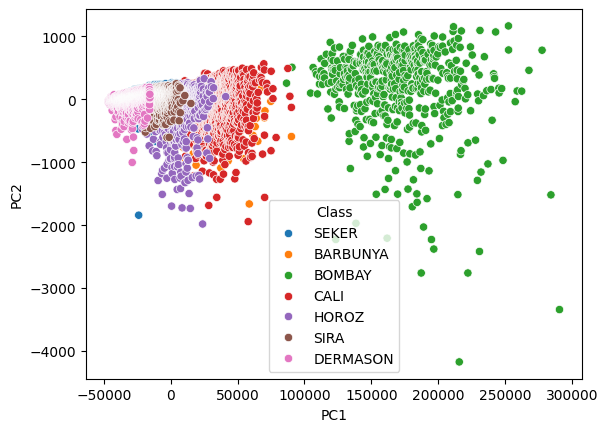

In [253]:
sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="Class")

Without proper scaling, the principal components do not reflect the data well.

In [254]:
standard_scaler = StandardScaler()

standard_features = standard_scaler.fit_transform(features)

standard_data = pd.DataFrame(data = standard_features , columns = features.columns)

In [255]:
principalComponents2 = pca.fit_transform(standard_features)

principal_data2 = pd.DataFrame(data = principalComponents2 , columns = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"])
pca_data2 = pd.concat([principal_data2, target], axis=1)

<Axes: xlabel='PC1', ylabel='PC2'>

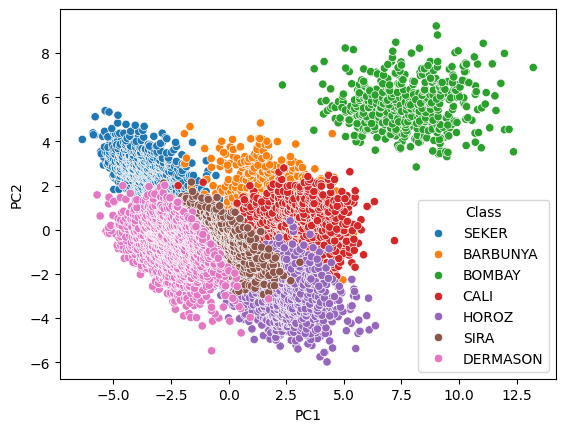

In [256]:
sns.scatterplot(data=pca_data2, x="PC1", y="PC2", hue="Class")

StandardScaler shows more promise with principal components

In [257]:
minmax_scaler = MinMaxScaler()

minmax_features = minmax_scaler.fit_transform(features)

minmax_data = pd.DataFrame(data = minmax_features , columns = features.columns)

In [258]:
principalComponents3 = pca.fit_transform(minmax_features)

principal_data3 = pd.DataFrame(data = principalComponents3 , columns = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"])
pca_data3 = pd.concat([principal_data3, target], axis=1)

<Axes: xlabel='PC1', ylabel='PC2'>

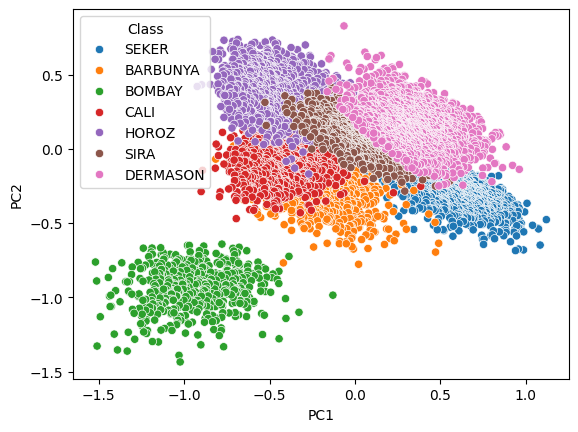

In [259]:
sns.scatterplot(data=pca_data3, x="PC1", y="PC2", hue="Class")

With minmax scaler, the principal components are more contained and seems to be mirrored and flipped.

In [260]:
PCA_model = PCA(n_components=6)
PCA_model.fit(minmax_features)
PCA_model.explained_variance_ratio_

array([0.60005569, 0.28171441, 0.06139866, 0.0239325 , 0.01467472,
       0.00971312])

In [261]:
lda = LinearDiscriminantAnalysis(n_components=6)

lda_features = lda.fit_transform(features, target)

lda_labelled = pd.DataFrame(data = lda_features , columns = ["LD1", "LD2", "LD3", "LD4", "LD5", "LD6"])

lda_data = pd.concat([lda_labelled, target], axis=1)

<Axes: xlabel='LD1', ylabel='LD2'>

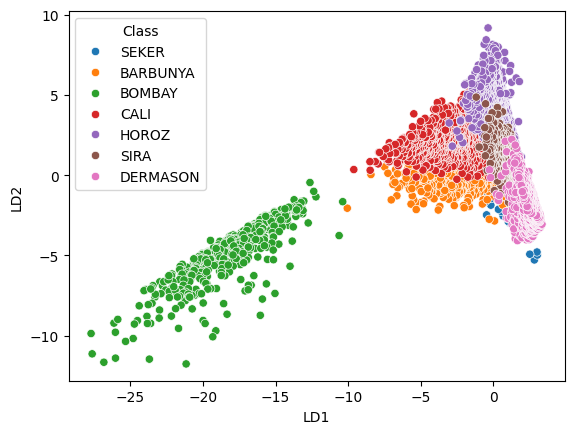

In [262]:
sns.scatterplot(data=lda_data, x="LD1", y="LD2", hue="Class")

Unscaled LDA produced similar slant as uscaled PCA.

In [263]:
lda_features2 = lda.fit_transform(standard_features, target)

lda_labelled2 = pd.DataFrame(data = lda_features2 , columns = ["LD1", "LD2", "LD3", "LD4", "LD5", "LD6"])

lda_data2 = pd.concat([lda_labelled2, target], axis=1)

<Axes: xlabel='LD1', ylabel='LD2'>

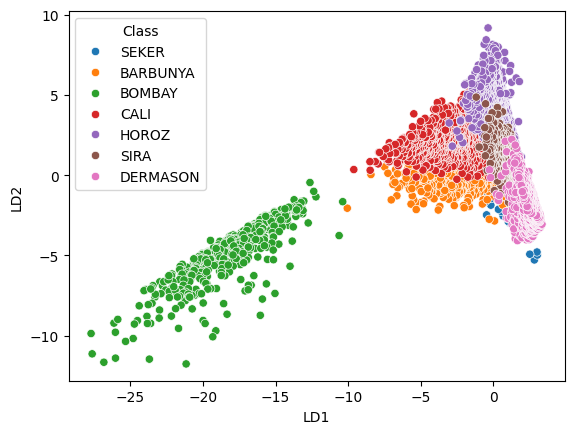

In [264]:
sns.scatterplot(data=lda_data2, x="LD1", y="LD2", hue="Class")

Standard scaler does not change LD1, LD2 too much

In [265]:
lda_features3 = lda.fit_transform(minmax_features, target)

lda_labelled3 = pd.DataFrame(data = lda_features3 , columns = ["LD1", "LD2", "LD3", "LD4", "LD5", "LD6"])

lda_data3 = pd.concat([lda_labelled3, target], axis=1)

<Axes: xlabel='LD1', ylabel='LD2'>

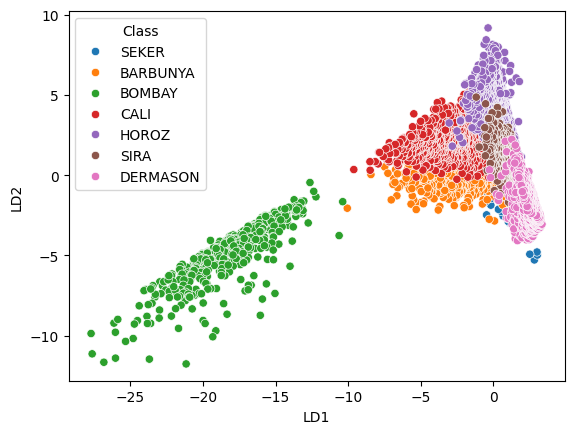

In [266]:
sns.scatterplot(data=lda_data3, x="LD1", y="LD2", hue="Class")

minmax scaler also does not change anything.

In [267]:
pca_data3.head()

,PC1,PC2,PC3,PC4,PC5,PC6,Class
0,0.840070,-0.181365,-0.074199,-0.021128,-0.030045,0.088796,SEKER
1,1.006579,-0.366748,-0.098566,-0.186345,0.079589,0.189854,SEKER
2,0.798926,-0.185865,-0.025051,-0.021419,-0.007362,0.082673,SEKER
3,0.845979,-0.275725,-0.064797,-0.243850,-0.013191,0.127964,SEKER
4,1.119803,-0.476853,-0.146292,-0.051970,-0.003066,0.110990,SEKER


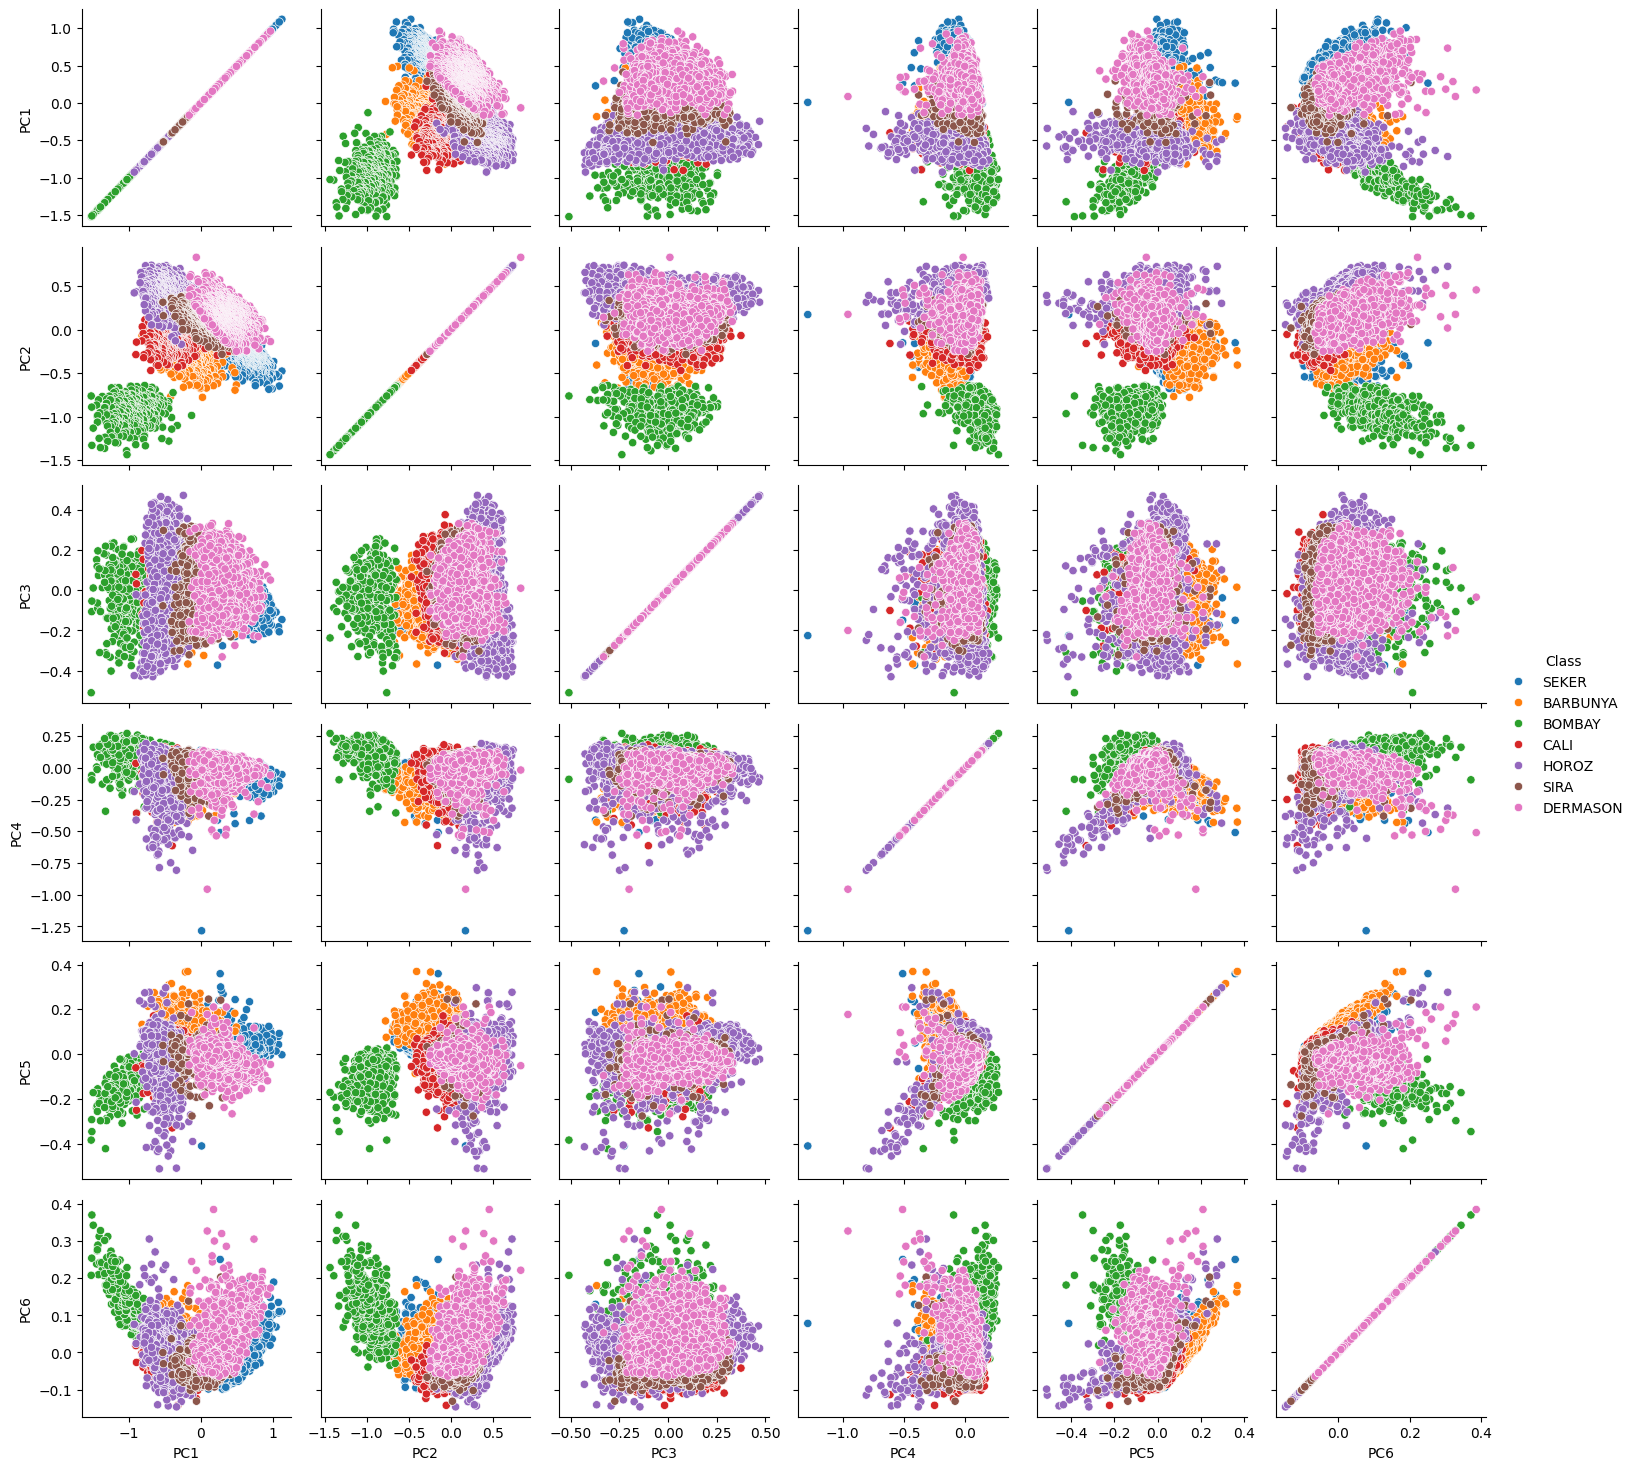

In [268]:
p = sns.PairGrid(pca_data3, hue="Class")
p.map(sns.scatterplot)
p.add_legend()

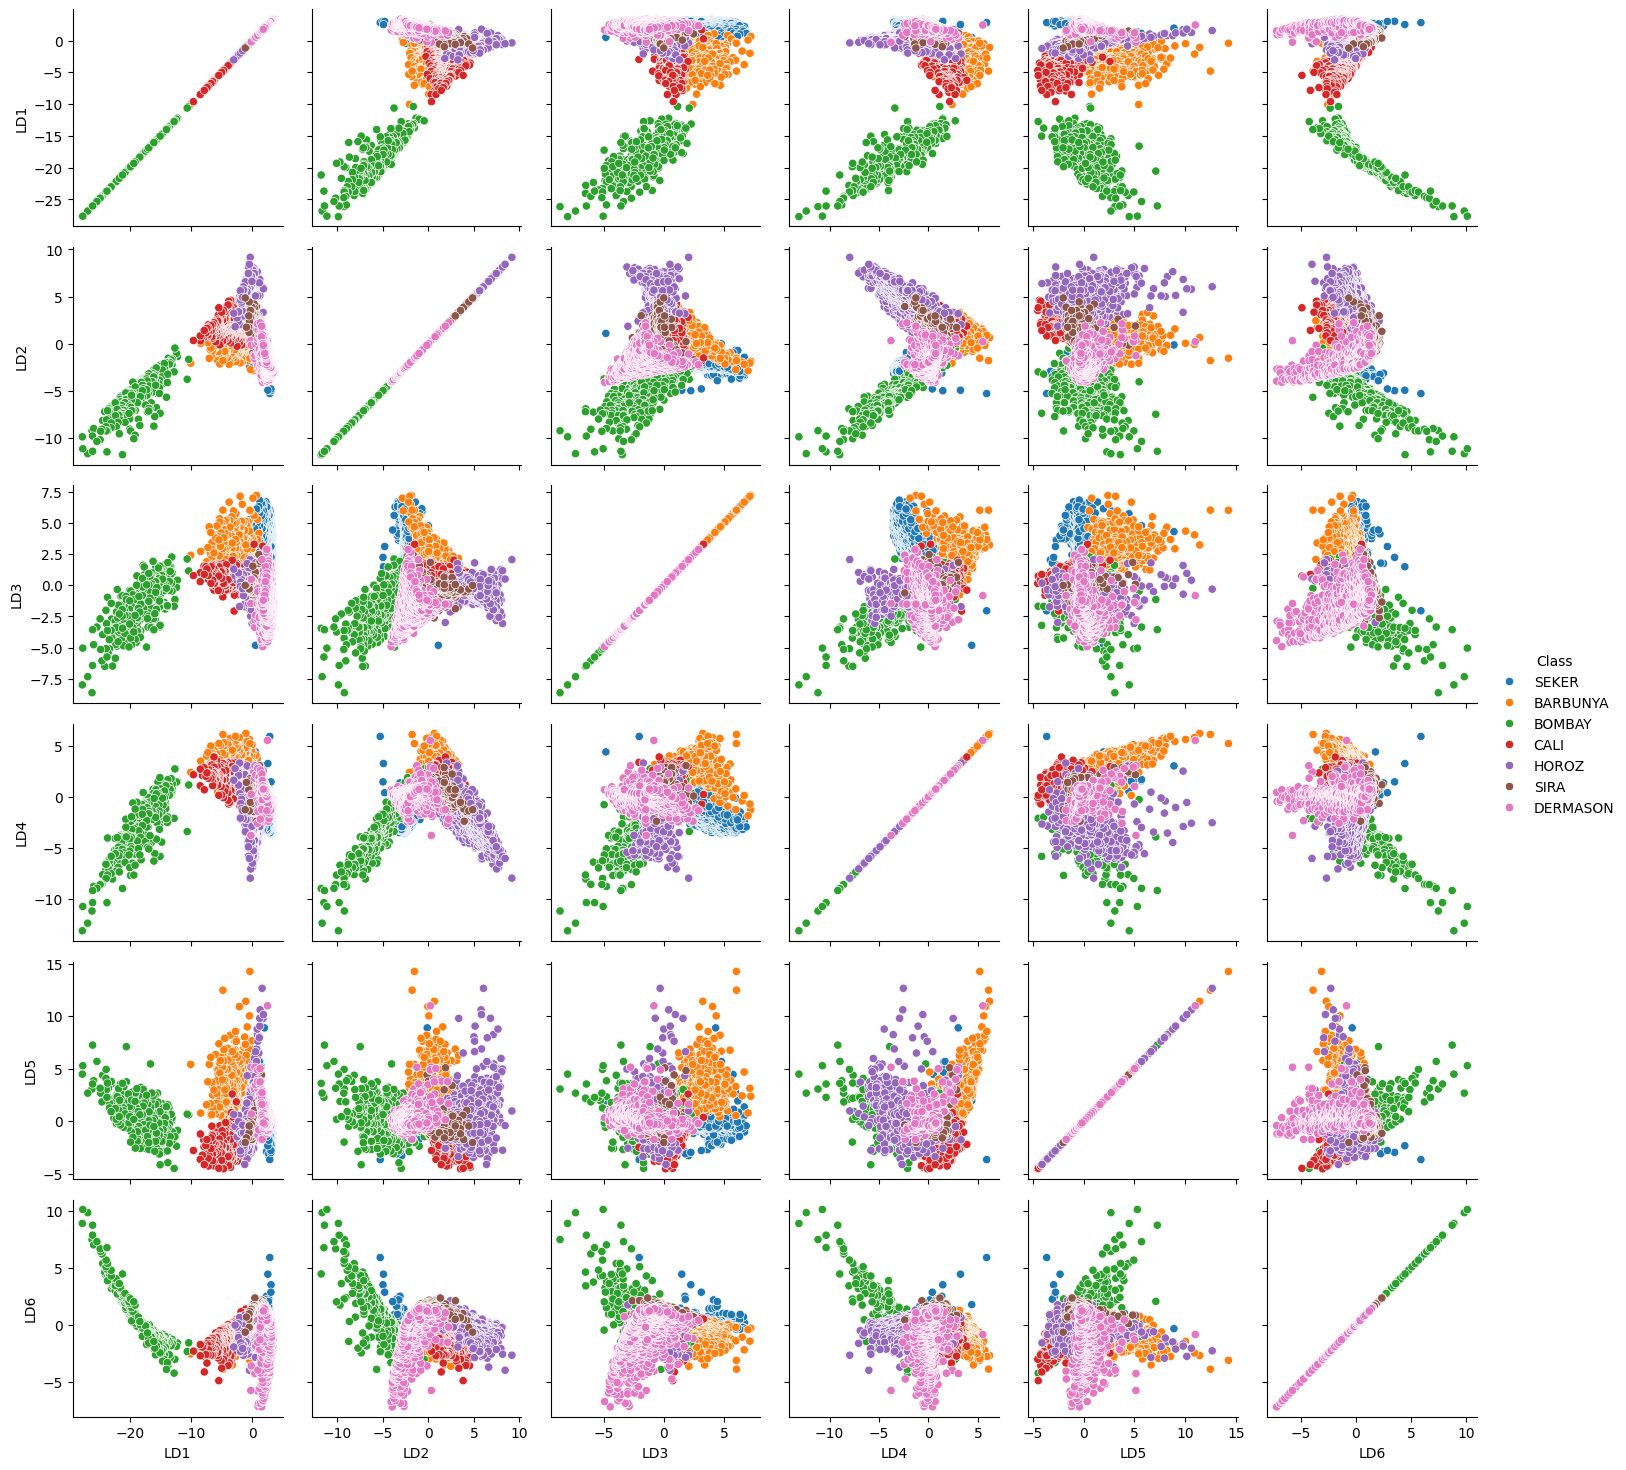

In [269]:
ld = sns.PairGrid(lda_data, hue="Class")
ld.map(sns.scatterplot)
ld.add_legend()

Issues: bi-serial correlation may not be an effective analytical tool.

Wrangling of PCA and LDA. What type of scaling? Dropping offending features to get it to work as preprocessing - minimal amount of features to have linear relationships, can help with other models too?

nonlinear PCA can be accomplished through neural network model with restriction in middle to create a latent spacce.

In [270]:
pca_features = pca_data3.drop(columns=["Class"])
lda_features = lda_data.drop(columns=["Class"])

<Axes: >

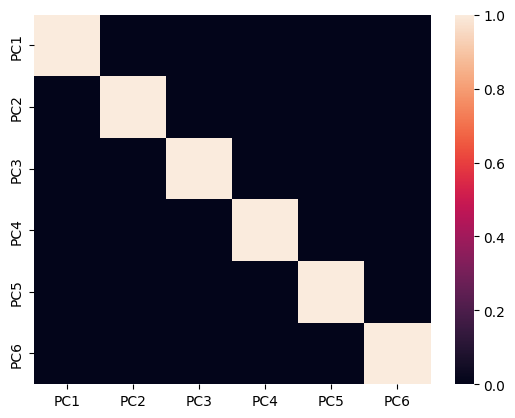

In [271]:
sns.heatmap(pca_features.corr())

<Axes: >

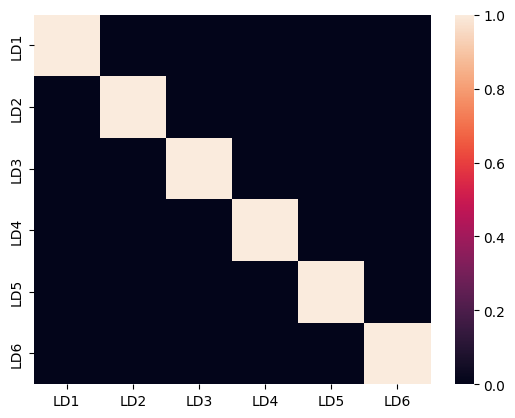

In [272]:
sns.heatmap(lda_features.corr())

### Modelling

In [273]:
scorers = ["f1_weighted", "f1_macro", "precision_weighted", "recall_weighted", "balanced_accuracy"]

There is features matrix, targets vector, bean_data, pca_data3, and lda_data.

Possible models from sklearn: decision tree (baseline?), extra tree (haven't used, for ensemble?), KNN, NearestCentroid, RandomForest, GradientBoosting, RadiusNeighbors (haven't used), gaussianNB (features fit gaussian distributions?), LabelPropagation/LabelSpreading (haven't heard of it), LDA (problem nonlinear covariance), QDA (extension from discussion), Perceptron.

Variations: weighing class, SMOTE, stratified sample

In [274]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.20)

In [275]:
rf_clf1 = RandomForestClassifier()
rf_clf2 = RandomForestClassifier(max_depth = 3, n_estimators = 100, min_samples_split = 3, class_weight="balanced", criterion="gini", max_features="log2")
rf_clf3 = RandomForestClassifier(max_depth = 3, n_estimators = 100, min_samples_split = 3, class_weight="balanced", max_features="log2")
rf_clf4 = RandomForestClassifier(max_depth = 3, min_samples_split = 3, min_samples_leaf = 5)

In [276]:
cv = StratifiedKFold(n_splits=5)

In [277]:
scores = cross_validate(rf_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for RandomForestClassifier is 6.9 +/- 0.64
score_time for RandomForestClassifier is 0.11 +/- 0.03
test_f1_weighted for RandomForestClassifier is 0.56 +/- 0.21
test_f1_macro for RandomForestClassifier is 0.64 +/- 0.19
test_precision_weighted for RandomForestClassifier is 0.58 +/- 0.22
test_recall_weighted for RandomForestClassifier is 0.62 +/- 0.19
test_balanced_accuracy for RandomForestClassifier is 0.68 +/- 0.18


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [278]:
scores = cross_validate(rf_clf2, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for RandomForestClassifier is 2.34 +/- 0.34
score_time for RandomForestClassifier is 0.07 +/- 0.02
test_f1_weighted for RandomForestClassifier is 0.78 +/- 0.16
test_f1_macro for RandomForestClassifier is 0.8 +/- 0.15
test_precision_weighted for RandomForestClassifier is 0.81 +/- 0.14
test_recall_weighted for RandomForestClassifier is 0.79 +/- 0.16
test_balanced_accuracy for RandomForestClassifier is 0.8 +/- 0.13


first acc: 0.8369445464561146

second acc: 0.855306647080426

third acc: 0.8380462724935732

fourth acc: 0.8479618068307014

fifth acc: 0.8523687109805361

In [279]:
#cm = confusion_matrix(y_test, y_pred, labels=rf_clf1.classes_)
#disp = ConfusionMatrixDisplay(cm, display_labels=rf_clf1.classes_)
#disp.plot()
#plt.show()

Problem: how to setup labelled multiclass confusion matrix

baseline randomForest is decently high acc. Class 1 is often confused as class 3 - low recall

In [280]:
pca_features = pca_data3.drop(columns=["Class"])

X_train, X_test, y_train, y_test = train_test_split(pca_features, target, test_size = 0.20)

In [281]:
scores = cross_validate(rf_clf1, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA RandomForestClassifier is 3.59 +/- 0.43
score_time for PCA RandomForestClassifier is 0.1 +/- 0.02
test_f1_weighted for PCA RandomForestClassifier is 0.82 +/- 0.16
test_f1_macro for PCA RandomForestClassifier is 0.86 +/- 0.12
test_precision_weighted for PCA RandomForestClassifier is 0.87 +/- 0.11
test_recall_weighted for PCA RandomForestClassifier is 0.84 +/- 0.14
test_balanced_accuracy for PCA RandomForestClassifier is 0.87 +/- 0.11


In [282]:
scores = cross_validate(rf_clf3, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA RandomForestClassifier is 1.42 +/- 0.23
score_time for PCA RandomForestClassifier is 0.1 +/- 0.02
test_f1_weighted for PCA RandomForestClassifier is 0.83 +/- 0.13
test_f1_macro for PCA RandomForestClassifier is 0.86 +/- 0.09
test_precision_weighted for PCA RandomForestClassifier is 0.87 +/- 0.08
test_recall_weighted for PCA RandomForestClassifier is 0.84 +/- 0.12
test_balanced_accuracy for PCA RandomForestClassifier is 0.86 +/- 0.08


first acc: 0.8703635695923614

second acc: 0.876239441792141

third acc: 0.879544619904517

pca baseline better acc

In [283]:
lda_features = lda_data.drop(columns=["Class"])

X_train, X_test, y_train, y_test = train_test_split(pca_features, target, test_size = 0.20)

In [284]:
scores = cross_validate(rf_clf1, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA RandomForestClassifier is 3.61 +/- 0.37
score_time for LDA RandomForestClassifier is 0.1 +/- 0.03
test_f1_weighted for LDA RandomForestClassifier is 0.78 +/- 0.18
test_f1_macro for LDA RandomForestClassifier is 0.81 +/- 0.15
test_precision_weighted for LDA RandomForestClassifier is 0.83 +/- 0.13
test_recall_weighted for LDA RandomForestClassifier is 0.8 +/- 0.17
test_balanced_accuracy for LDA RandomForestClassifier is 0.83 +/- 0.14


In [285]:
scores = cross_validate(rf_clf4, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA RandomForestClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA RandomForestClassifier is 1.22 +/- 0.02
score_time for LDA RandomForestClassifier is 0.07 +/- 0.0
test_f1_weighted for LDA RandomForestClassifier is 0.83 +/- 0.14
test_f1_macro for LDA RandomForestClassifier is 0.83 +/- 0.13
test_precision_weighted for LDA RandomForestClassifier is 0.87 +/- 0.1
test_recall_weighted for LDA RandomForestClassifier is 0.84 +/- 0.13
test_balanced_accuracy for LDA RandomForestClassifier is 0.83 +/- 0.13


first acc: 0.8725670216672787

second acc: 0.8736687477047375

third acc: 0.8865222181417555

lda comparable to pca

In [286]:
dt_clf1 = DecisionTreeClassifier(criterion="gini", min_samples_split=3)

In [287]:
scores = cross_validate(dt_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for DecisionTreeClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for DecisionTreeClassifier is 0.51 +/- 0.09
score_time for DecisionTreeClassifier is 0.08 +/- 0.02
test_f1_weighted for DecisionTreeClassifier is 0.5 +/- 0.19
test_f1_macro for DecisionTreeClassifier is 0.58 +/- 0.18
test_precision_weighted for DecisionTreeClassifier is 0.59 +/- 0.15
test_recall_weighted for DecisionTreeClassifier is 0.56 +/- 0.18
test_balanced_accuracy for DecisionTreeClassifier is 0.64 +/- 0.17


In [288]:
scores = cross_validate(dt_clf1, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA DecisionTreeClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA DecisionTreeClassifier is 0.21 +/- 0.01
score_time for PCA DecisionTreeClassifier is 0.09 +/- 0.0
test_f1_weighted for PCA DecisionTreeClassifier is 0.76 +/- 0.16
test_f1_macro for PCA DecisionTreeClassifier is 0.8 +/- 0.13
test_precision_weighted for PCA DecisionTreeClassifier is 0.81 +/- 0.11
test_recall_weighted for PCA DecisionTreeClassifier is 0.77 +/- 0.14
test_balanced_accuracy for PCA DecisionTreeClassifier is 0.81 +/- 0.12


In [289]:
scores = cross_validate(dt_clf1, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA DecisionTreeClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA DecisionTreeClassifier is 0.21 +/- 0.03
score_time for LDA DecisionTreeClassifier is 0.08 +/- 0.02
test_f1_weighted for LDA DecisionTreeClassifier is 0.74 +/- 0.18
test_f1_macro for LDA DecisionTreeClassifier is 0.77 +/- 0.15
test_precision_weighted for LDA DecisionTreeClassifier is 0.79 +/- 0.12
test_recall_weighted for LDA DecisionTreeClassifier is 0.75 +/- 0.16
test_balanced_accuracy for LDA DecisionTreeClassifier is 0.79 +/- 0.14


DecisionTree performs as expected (Not that well). BUT, PCA/LDA decision tree performs suprising decently. Comparable to baseline RandomForest which is odd.

In [290]:
knn_clf1 = KNeighborsClassifier(n_neighbors=5)
knn_clf2 = KNeighborsClassifier(n_neighbors=7, weights="distance", algorithm="ball_tree")

In [291]:
scores = cross_validate(knn_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for KNeighborsClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for KNeighborsClassifier is 0.01 +/- 0.0
score_time for KNeighborsClassifier is 0.27 +/- 0.01
test_f1_weighted for KNeighborsClassifier is 0.12 +/- 0.04
test_f1_macro for KNeighborsClassifier is 0.2 +/- 0.02
test_precision_weighted for KNeighborsClassifier is 0.17 +/- 0.09
test_recall_weighted for KNeighborsClassifier is 0.15 +/- 0.08
test_balanced_accuracy for KNeighborsClassifier is 0.22 +/- 0.04


In [292]:
scores = cross_validate(knn_clf2, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA KNeighborsClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA KNeighborsClassifier is 0.02 +/- 0.0
score_time for PCA KNeighborsClassifier is 0.19 +/- 0.02
test_f1_weighted for PCA KNeighborsClassifier is 0.83 +/- 0.13
test_f1_macro for PCA KNeighborsClassifier is 0.86 +/- 0.1
test_precision_weighted for PCA KNeighborsClassifier is 0.87 +/- 0.09
test_recall_weighted for PCA KNeighborsClassifier is 0.84 +/- 0.12
test_balanced_accuracy for PCA KNeighborsClassifier is 0.86 +/- 0.09


In [293]:
scores = cross_validate(knn_clf2, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA KNeighborsClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA KNeighborsClassifier is 0.02 +/- 0.0
score_time for LDA KNeighborsClassifier is 0.18 +/- 0.02
test_f1_weighted for LDA KNeighborsClassifier is 0.81 +/- 0.14
test_f1_macro for LDA KNeighborsClassifier is 0.84 +/- 0.11
test_precision_weighted for LDA KNeighborsClassifier is 0.85 +/- 0.09
test_recall_weighted for LDA KNeighborsClassifier is 0.82 +/- 0.12
test_balanced_accuracy for LDA KNeighborsClassifier is 0.85 +/- 0.1


KNN does NOT work well for baseline data. This can be explained from major overlap of classes. With PCA/LDA, they work much better. PCA is slightly better than LDA which is interesting since it maximizes for variance while LDA maximizes distance.

5 neighbors improves performance .82/.84/.8

In [294]:
nc_clf1 = NearestCentroid()
nc_clf2 = NearestCentroid(metric="manhattan")

In [295]:
scores = cross_validate(nc_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for NearestCentroidClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


fit_time for NearestCentroidClassifier is 0.02 +/- 0.0
score_time for NearestCentroidClassifier is 0.05 +/- 0.0
test_f1_weighted for NearestCentroidClassifier is 0.51 +/- 0.32
test_f1_macro for NearestCentroidClassifier is 0.54 +/- 0.28
test_precision_weighted for NearestCentroidClassifier is 0.5 +/- 0.33
test_recall_weighted for NearestCentroidClassifier is 0.55 +/- 0.3
test_balanced_accuracy for NearestCentroidClassifier is 0.58 +/- 0.27


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [296]:
scores = cross_validate(nc_clf2, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA NearestCentroidClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA NearestCentroidClassifier is 0.01 +/- 0.0
score_time for PCA NearestCentroidClassifier is 0.05 +/- 0.0
test_f1_weighted for PCA NearestCentroidClassifier is 0.83 +/- 0.11
test_f1_macro for PCA NearestCentroidClassifier is 0.86 +/- 0.08
test_precision_weighted for PCA NearestCentroidClassifier is 0.87 +/- 0.06
test_recall_weighted for PCA NearestCentroidClassifier is 0.84 +/- 0.1
test_balanced_accuracy for PCA NearestCentroidClassifier is 0.87 +/- 0.07


In [297]:
scores = cross_validate(nc_clf2, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA NearestCentroidClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA NearestCentroidClassifier is 0.01 +/- 0.0
score_time for LDA NearestCentroidClassifier is 0.05 +/- 0.0
test_f1_weighted for LDA NearestCentroidClassifier is 0.87 +/- 0.12
test_f1_macro for LDA NearestCentroidClassifier is 0.89 +/- 0.08
test_precision_weighted for LDA NearestCentroidClassifier is 0.91 +/- 0.07
test_recall_weighted for LDA NearestCentroidClassifier is 0.88 +/- 0.11
test_balanced_accuracy for LDA NearestCentroidClassifier is 0.89 +/- 0.08


Base NearestCentroid works better than KNN. With PCA and LDA, it works comparable to KNN. Interestingly, LDA nearest centroid is better than both PCA/LDA KNN. This makes sense since LDA maximizes distance between the groups.

In [298]:
gb_clf1 = GradientBoostingClassifier(n_estimators=30, learning_rate=.1, max_depth=3)

In [299]:
scores = cross_validate(gb_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for GradientBoostingClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for GradientBoostingClassifier is 24.31 +/- 0.45
score_time for GradientBoostingClassifier is 0.08 +/- 0.02
test_f1_weighted for GradientBoostingClassifier is 0.69 +/- 0.27
test_f1_macro for GradientBoostingClassifier is 0.73 +/- 0.24
test_precision_weighted for GradientBoostingClassifier is 0.69 +/- 0.28
test_recall_weighted for GradientBoostingClassifier is 0.72 +/- 0.24
test_balanced_accuracy for GradientBoostingClassifier is 0.75 +/- 0.22


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [300]:
scores = cross_validate(gb_clf1, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA GradientBoostingClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA GradientBoostingClassifier is 9.97 +/- 0.38
score_time for PCA GradientBoostingClassifier is 0.08 +/- 0.02
test_f1_weighted for PCA GradientBoostingClassifier is 0.83 +/- 0.16
test_f1_macro for PCA GradientBoostingClassifier is 0.87 +/- 0.12
test_precision_weighted for PCA GradientBoostingClassifier is 0.88 +/- 0.11
test_recall_weighted for PCA GradientBoostingClassifier is 0.85 +/- 0.14
test_balanced_accuracy for PCA GradientBoostingClassifier is 0.87 +/- 0.11


In [301]:
scores = cross_validate(gb_clf1, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA GradientBoostingClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA GradientBoostingClassifier is 9.9 +/- 0.34
score_time for LDA GradientBoostingClassifier is 0.07 +/- 0.02
test_f1_weighted for LDA GradientBoostingClassifier is 0.81 +/- 0.19
test_f1_macro for LDA GradientBoostingClassifier is 0.84 +/- 0.16
test_precision_weighted for LDA GradientBoostingClassifier is 0.85 +/- 0.14
test_recall_weighted for LDA GradientBoostingClassifier is 0.82 +/- 0.18
test_balanced_accuracy for LDA GradientBoostingClassifier is 0.84 +/- 0.15


baseline gradientboosting works slightly worse than randomForest. |||

Adjusted to max_depth=2, learning_rate=.8 also does not work great. PCA acc: .82 +/- .15, PCA f1_macro: .84 +/- .14, PCA f1_weighted: .8 +/- .17. LDA acc: .71 +/0 .31, LDA f1_macro: .69 +/- .34, LDA f1_weighted: .69 +/- .32.

n_estimators=30, learning_rate=.2, max_depth=2. acc: .75 +/- .21, f1_macro: .75 +/- .21, f1_weighted: .71 +/- .25. PCA acc: .85 +/- .14, PCA f1_macro: .87 +/- .12, PCA f1_weighted: .84 +/- .16. LDA acc: .83 +/- .17, LDA f1_macro .84 +/- .16, LDA f1_weighted: .81 +/- .19.

n_estimators=100, learning_rate =.1, max_depth=3. acc: .68 +/- .21, f1_macro: .7 +/- .22, f1_weighted .65 +/- .25. PCA acc: .85 +/- .14, PCA f1_macro: .86 +/- .12, f1_weighted: .83 +/- .16, LDA acc: .81 +/- .18, LDA f1_macro: .82 +/- .16, LDA f1_weighted .8 +/- .2

computationally expenisive overall. base level 20 mins, others 8 mins each

n_estimators=30, learning_rate=.1, max_depth=3. acc: .72 +/- .24, f1_macro: .73 +/- .24, f1_weighted: .69 +/- .27. PCA acc: .85 +/- .14, PCA f1_macro: .87 +/- .12, PCA weighted: .83 +/- .16. LDA acc: .82 +/- .18, LDA f1_macro: .84 +/- .16, LDA f1_weighted .81 +/- .19

In [302]:
rn_clf1 = RadiusNeighborsClassifier(radius=.723, weights="distance", outlier_label="most_frequent")
rn_clf2 = RadiusNeighborsClassifier(radius=2.75, weights="distance", outlier_label="most_frequent")

In [303]:
"""

for scorer in scorers:
  score = cross_val_score(rn_clf1, features, target, scoring=scorer, cv=cv)
  print(f"{scorer} for RadiusNeighborsClassifier is {round(score.mean(), 2)} +/- {round(np.std(score), 2)}")

"""

'\n\nfor scorer in scorers:\n  score = cross_val_score(rn_clf1, features, target, scoring=scorer, cv=cv)\n  print(f"{scorer} for RadiusNeighborsClassifier is {round(score.mean(), 2)} +/- {round(np.std(score), 2)}")\n\n'

In [304]:
scores = cross_validate(rn_clf1, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA RadiusNeighborsClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA RadiusNeighborsClassifier is 0.02 +/- 0.0
score_time for PCA RadiusNeighborsClassifier is 1.06 +/- 0.36
test_f1_weighted for PCA RadiusNeighborsClassifier is 0.74 +/- 0.12
test_f1_macro for PCA RadiusNeighborsClassifier is 0.74 +/- 0.11
test_precision_weighted for PCA RadiusNeighborsClassifier is 0.8 +/- 0.12
test_recall_weighted for PCA RadiusNeighborsClassifier is 0.77 +/- 0.11
test_balanced_accuracy for PCA RadiusNeighborsClassifier is 0.75 +/- 0.11


radius of 3.0 basically caused model to always guess majority class. 1.0 a bit better. .8 improves it. .75 | .43, .39, .36. || .73 | .45, .41, .38 || .71 errors || .72 errors || .725 | .45, .42, .38 || .723 | .45, .42, .39 || radius=.723, weights="distance" | .77, .74, .74 || radius=1, weights="dsitance | .75, .69, .71

In [305]:
scores = cross_validate(rn_clf2, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA RadiusNeighborsClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA RadiusNeighborsClassifier is 0.03 +/- 0.01
score_time for LDA RadiusNeighborsClassifier is 0.51 +/- 0.1
test_f1_weighted for LDA RadiusNeighborsClassifier is 0.86 +/- 0.13
test_f1_macro for LDA RadiusNeighborsClassifier is 0.88 +/- 0.1
test_precision_weighted for LDA RadiusNeighborsClassifier is 0.88 +/- 0.1
test_recall_weighted for LDA RadiusNeighborsClassifier is 0.87 +/- 0.12
test_balanced_accuracy for LDA RadiusNeighborsClassifier is 0.87 +/- 0.1


radius=5, weights="distance", outlier_label="most_frequent" | .85 +/- .12, .86 +/- .11, .84 +/- .13 ||

radius=3, weights="distance", outlier_label="most_frequent" | .86 +/- .11, .88 +/- .1, .86 +/- .12 ||

radius=1, worse than recorded

radius=2, comparrable to radius=3


radius=2.75, weights="distance", outlier_label="most_frequent" | .87 +/- .12, .88 +/- .1, .86 +/- .13 ||



In [306]:
gnb_clf1 = GaussianNB()

In [307]:
scores = cross_validate(gnb_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for GaussianNBClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


fit_time for GaussianNBClassifier is 0.03 +/- 0.0
score_time for GaussianNBClassifier is 0.08 +/- 0.0
test_f1_weighted for GaussianNBClassifier is 0.64 +/- 0.35
test_f1_macro for GaussianNBClassifier is 0.66 +/- 0.31
test_precision_weighted for GaussianNBClassifier is 0.69 +/- 0.32
test_recall_weighted for GaussianNBClassifier is 0.67 +/- 0.32
test_balanced_accuracy for GaussianNBClassifier is 0.68 +/- 0.28


independence assumption for base features likely not present.

In [308]:
scores = cross_validate(gnb_clf1, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA GaussianNBClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA GaussianNBClassifier is 0.03 +/- 0.0
score_time for PCA GaussianNBClassifier is 0.08 +/- 0.0
test_f1_weighted for PCA GaussianNBClassifier is 0.84 +/- 0.14
test_f1_macro for PCA GaussianNBClassifier is 0.88 +/- 0.09
test_precision_weighted for PCA GaussianNBClassifier is 0.89 +/- 0.08
test_recall_weighted for PCA GaussianNBClassifier is 0.86 +/- 0.12
test_balanced_accuracy for PCA GaussianNBClassifier is 0.88 +/- 0.08


PCA scores are great.

In [309]:
scores = cross_validate(gnb_clf1, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA GaussianNBClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA GaussianNBClassifier is 0.03 +/- 0.0
score_time for LDA GaussianNBClassifier is 0.08 +/- 0.0
test_f1_weighted for LDA GaussianNBClassifier is 0.88 +/- 0.11
test_f1_macro for LDA GaussianNBClassifier is 0.9 +/- 0.08
test_precision_weighted for LDA GaussianNBClassifier is 0.9 +/- 0.07
test_recall_weighted for LDA GaussianNBClassifier is 0.88 +/- 0.1
test_balanced_accuracy for LDA GaussianNBClassifier is 0.9 +/- 0.07


LDA scores even better

In [310]:
lp_clf1 = LabelPropagation()

In [311]:
"""

for scorer in scorers:
  score = cross_val_score(lp_clf1, features, target, scoring=scorer, cv=cv)
  print(f"{scorer} for LabelPropagationClassifier is {round(score.mean(), 2)} +/- {round(np.std(score), 2)}")

"""

'\n\nfor scorer in scorers:\n  score = cross_val_score(lp_clf1, features, target, scoring=scorer, cv=cv)\n  print(f"{scorer} for LabelPropagationClassifier is {round(score.mean(), 2)} +/- {round(np.std(score), 2)}")\n\n'

label propagation errors out.

In [312]:
mlp_clf1 = MLPClassifier(hidden_layer_sizes=(8,))
mlp_clf2 = MLPClassifier(hidden_layer_sizes=(3,))

In [313]:
scores = cross_validate(mlp_clf1, features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for MLPClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

fit_time for MLPClassifier is 2.31 +/- 0.88
score_time for MLPClassifier is 0.06 +/- 0.02
test_f1_weighted for MLPClassifier is 0.21 +/- 0.09
test_f1_macro for MLPClassifier is 0.2 +/- 0.1
test_precision_weighted for MLPClassifier is 0.22 +/- 0.12
test_recall_weighted for MLPClassifier is 0.31 +/- 0.1
test_balanced_accuracy for MLPClassifier is 0.27 +/- 0.11


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [314]:
scores = cross_validate(mlp_clf2, pca_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for PCA MLPClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for PCA MLPClassifier is 5.37 +/- 0.86
score_time for PCA MLPClassifier is 0.05 +/- 0.01
test_f1_weighted for PCA MLPClassifier is 0.82 +/- 0.18
test_f1_macro for PCA MLPClassifier is 0.85 +/- 0.14
test_precision_weighted for PCA MLPClassifier is 0.87 +/- 0.13
test_recall_weighted for PCA MLPClassifier is 0.84 +/- 0.15
test_balanced_accuracy for PCA MLPClassifier is 0.86 +/- 0.12


In [315]:
scores = cross_validate(mlp_clf2, lda_features, target, scoring=scorers, cv=cv)

for score in scores:
  print(f"{score} for LDA MLPClassifier is {round(scores[score].mean(), 2)} +/- {round(np.std(scores[score]), 2)}")

fit_time for LDA MLPClassifier is 5.6 +/- 0.78
score_time for LDA MLPClassifier is 0.06 +/- 0.02
test_f1_weighted for LDA MLPClassifier is 0.83 +/- 0.16
test_f1_macro for LDA MLPClassifier is 0.86 +/- 0.13
test_precision_weighted for LDA MLPClassifier is 0.86 +/- 0.12
test_recall_weighted for LDA MLPClassifier is 0.84 +/- 0.14
test_balanced_accuracy for LDA MLPClassifier is 0.86 +/- 0.12


Stuff for train/test classifications

In [316]:
base_X_train, base_X_test, base_y_train, base_y_test = train_test_split(features, target, test_size = 0.30, stratify=target)
pca_X_train, pca_X_test, pca_y_train, pca_y_test = train_test_split(pca_features, target, test_size = 0.30, stratify=target)
lda_X_train, lda_X_test, lda_y_train, lda_y_test = train_test_split(lda_features, target, test_size = 0.30, stratify=target)

BASE DATA MODELS

In [317]:
rf_clf1.fit(base_X_train, base_y_train)
rf_clf2.fit(base_X_train, base_y_train)
dt_clf1.fit(base_X_train, base_y_train)
knn_clf1.fit(base_X_train, base_y_train)
nc_clf1.fit(base_X_train, base_y_train)
gb_clf1.fit(base_X_train, base_y_train)
gnb_clf1.fit(base_X_train, base_y_train)
mlp_clf1.fit(base_X_train, base_y_train)

MLPClassifier(hidden_layer_sizes=(8,))

In [318]:
rf_clf1_train_y = rf_clf1.predict(base_X_train)
rf_clf1_test_y = rf_clf1.predict(base_X_test)

In [319]:
print(classification_report(base_y_train, rf_clf1_train_y, target_names=rf_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [320]:
print(classification_report(base_y_test, rf_clf1_test_y, target_names=rf_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.93      0.93      0.93       489
    DERMASON       0.91      0.92      0.92      1064
       HOROZ       0.95      0.96      0.95       578
       SEKER       0.93      0.95      0.94       608
        SIRA       0.86      0.86      0.86       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



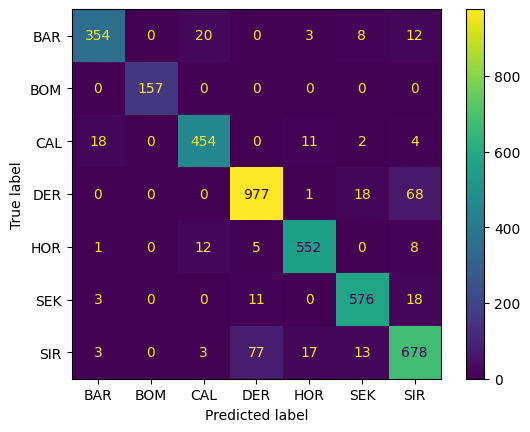

In [321]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, rf_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [322]:
rf_clf2_train_y = rf_clf2.predict(base_X_train)
rf_clf2_test_y = rf_clf2.predict(base_X_test)

In [323]:
print(classification_report(base_y_train, rf_clf2_train_y, target_names=rf_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.83      0.72      0.77       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.82      0.87      0.84      1141
    DERMASON       0.86      0.88      0.87      2482
       HOROZ       0.90      0.94      0.92      1350
       SEKER       0.89      0.91      0.90      1419
        SIRA       0.82      0.78      0.80      1845

    accuracy                           0.86      9527
   macro avg       0.87      0.87      0.87      9527
weighted avg       0.86      0.86      0.86      9527



In [324]:
print(classification_report(base_y_test, rf_clf2_test_y, target_names=rf_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.80      0.68      0.74       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.79      0.85      0.82       489
    DERMASON       0.86      0.88      0.87      1064
       HOROZ       0.88      0.94      0.91       578
       SEKER       0.91      0.90      0.91       608
        SIRA       0.79      0.76      0.78       791

    accuracy                           0.85      4084
   macro avg       0.86      0.86      0.86      4084
weighted avg       0.85      0.85      0.85      4084



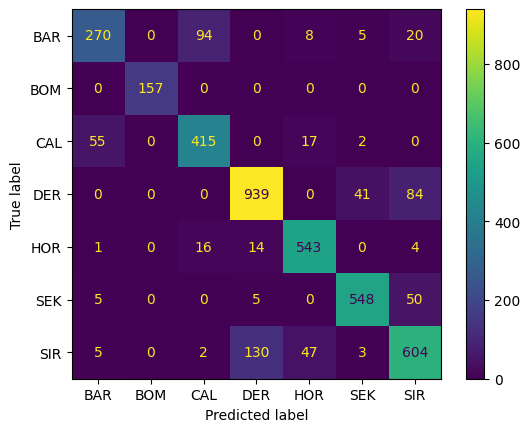

In [325]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, rf_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [326]:
dt_clf1_train_y = dt_clf1.predict(base_X_train)
dt_clf1_test_y = dt_clf1.predict(base_X_test)

In [327]:
print(classification_report(base_y_train, dt_clf1_train_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.99      1.00      0.99       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.99      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      0.99      1.00      1419
        SIRA       1.00      0.99      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [328]:
print(classification_report(base_y_test, dt_clf1_test_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.88      0.87      0.88       397
      BOMBAY       0.99      1.00      0.99       157
        CALI       0.91      0.91      0.91       489
    DERMASON       0.88      0.89      0.88      1064
       HOROZ       0.92      0.94      0.93       578
       SEKER       0.93      0.92      0.93       608
        SIRA       0.81      0.81      0.81       791

    accuracy                           0.89      4084
   macro avg       0.90      0.91      0.90      4084
weighted avg       0.89      0.89      0.89      4084



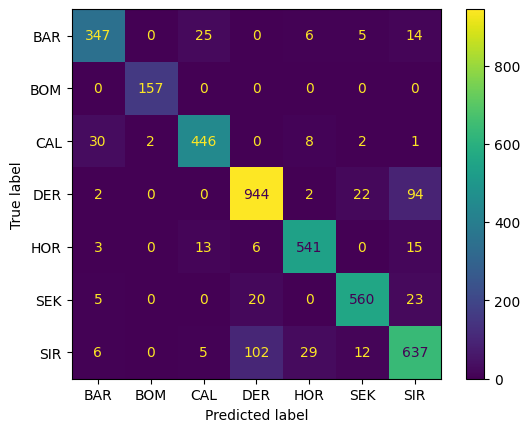

In [329]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, dt_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [330]:
knn_clf1_train_y = knn_clf1.predict(base_X_train)
knn_clf1_test_y = knn_clf1.predict(base_X_test)

In [331]:
print(classification_report(base_y_train, knn_clf1_train_y, target_names=knn_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.67      0.66      0.67       925
      BOMBAY       0.99      1.00      1.00       365
        CALI       0.76      0.77      0.77      1141
    DERMASON       0.85      0.94      0.89      2482
       HOROZ       0.81      0.77      0.79      1350
       SEKER       0.89      0.71      0.79      1419
        SIRA       0.77      0.80      0.79      1845

    accuracy                           0.81      9527
   macro avg       0.82      0.81      0.81      9527
weighted avg       0.81      0.81      0.81      9527



In [332]:
print(classification_report(base_y_test, knn_clf1_test_y, target_names=knn_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.50      0.48      0.49       397
      BOMBAY       0.99      1.00      0.99       157
        CALI       0.65      0.67      0.66       489
    DERMASON       0.79      0.89      0.84      1064
       HOROZ       0.69      0.66      0.67       578
       SEKER       0.77      0.58      0.66       608
        SIRA       0.67      0.71      0.69       791

    accuracy                           0.71      4084
   macro avg       0.72      0.71      0.71      4084
weighted avg       0.71      0.71      0.71      4084



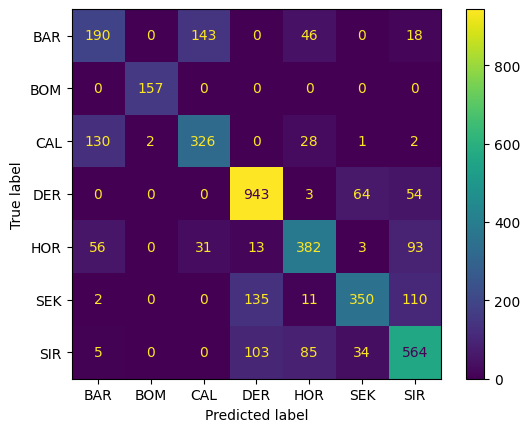

In [333]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, knn_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [334]:
nc_clf1_train_y = nc_clf1.predict(base_X_train)
nc_clf1_test_y = nc_clf1.predict(base_X_test)

In [335]:
print(classification_report(base_y_train, nc_clf1_train_y, target_names=nc_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.41      0.42      0.41       925
      BOMBAY       1.00      0.99      1.00       365
        CALI       0.66      0.59      0.62      1141
    DERMASON       0.84      0.77      0.80      2482
       HOROZ       0.58      0.61      0.59      1350
       SEKER       0.39      0.52      0.45      1419
        SIRA       0.62      0.53      0.57      1845

    accuracy                           0.62      9527
   macro avg       0.64      0.63      0.64      9527
weighted avg       0.64      0.62      0.62      9527



In [336]:
print(classification_report(base_y_test, nc_clf1_test_y, target_names=nc_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.42      0.44      0.43       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.68      0.59      0.63       489
    DERMASON       0.85      0.76      0.80      1064
       HOROZ       0.57      0.64      0.60       578
       SEKER       0.38      0.52      0.44       608
        SIRA       0.61      0.51      0.56       791

    accuracy                           0.62      4084
   macro avg       0.64      0.64      0.64      4084
weighted avg       0.64      0.62      0.62      4084



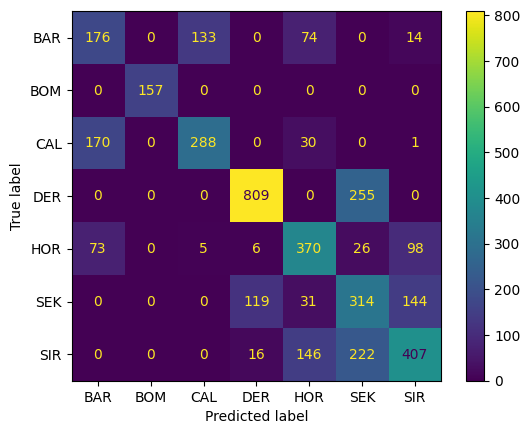

In [337]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, nc_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [338]:
gb_clf1_train_y = gb_clf1.predict(base_X_train)
gb_clf1_test_y = gb_clf1.predict(base_X_test)

In [339]:
print(classification_report(base_y_train, gb_clf1_train_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.97      0.94      0.95       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.96      0.97      0.96      1141
    DERMASON       0.92      0.94      0.93      2482
       HOROZ       0.97      0.96      0.97      1350
       SEKER       0.97      0.95      0.96      1419
        SIRA       0.89      0.89      0.89      1845

    accuracy                           0.94      9527
   macro avg       0.95      0.95      0.95      9527
weighted avg       0.94      0.94      0.94      9527



In [340]:
print(classification_report(base_y_test, gb_clf1_test_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.87      0.90       397
      BOMBAY       1.00      0.99      0.99       157
        CALI       0.92      0.93      0.92       489
    DERMASON       0.91      0.92      0.92      1064
       HOROZ       0.95      0.96      0.96       578
       SEKER       0.94      0.94      0.94       608
        SIRA       0.86      0.86      0.86       791

    accuracy                           0.92      4084
   macro avg       0.93      0.92      0.93      4084
weighted avg       0.92      0.92      0.92      4084



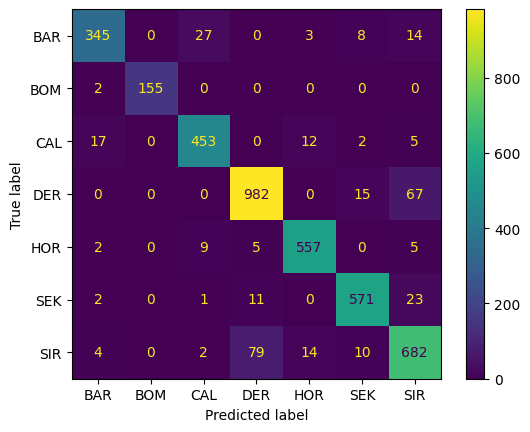

In [341]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, gb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [342]:
gnb_clf1_train_y = gnb_clf1.predict(base_X_train)
gnb_clf1_test_y = gnb_clf1.predict(base_X_test)

In [343]:
print(classification_report(base_y_train, gnb_clf1_train_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.64      0.48      0.55       925
      BOMBAY       0.99      1.00      1.00       365
        CALI       0.68      0.79      0.73      1141
    DERMASON       0.86      0.84      0.85      2482
       HOROZ       0.77      0.77      0.77      1350
       SEKER       0.69      0.72      0.70      1419
        SIRA       0.75      0.78      0.76      1845

    accuracy                           0.76      9527
   macro avg       0.77      0.77      0.77      9527
weighted avg       0.76      0.76      0.76      9527



In [344]:
print(classification_report(base_y_test, gnb_clf1_test_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.64      0.49      0.55       397
      BOMBAY       0.99      1.00      0.99       157
        CALI       0.69      0.78      0.73       489
    DERMASON       0.88      0.82      0.85      1064
       HOROZ       0.76      0.79      0.78       578
       SEKER       0.68      0.72      0.70       608
        SIRA       0.73      0.77      0.75       791

    accuracy                           0.76      4084
   macro avg       0.77      0.77      0.76      4084
weighted avg       0.76      0.76      0.76      4084



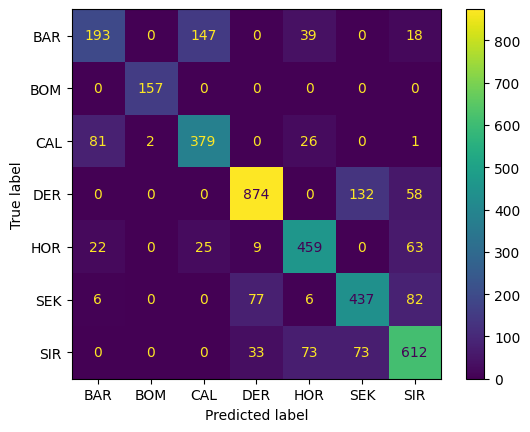

In [345]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, gnb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [346]:
mlp_clf1_train_y = mlp_clf1.predict(base_X_train)
mlp_clf1_test_y = mlp_clf1.predict(base_X_test)

In [347]:
print(classification_report(base_y_train, mlp_clf1_train_y, target_names=mlp_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.00      0.00      0.00       925
      BOMBAY       0.83      0.96      0.89       365
        CALI       0.00      0.00      0.00      1141
    DERMASON       0.27      1.00      0.43      2482
       HOROZ       0.00      0.00      0.00      1350
       SEKER       0.00      0.00      0.00      1419
        SIRA       0.00      0.00      0.00      1845

    accuracy                           0.30      9527
   macro avg       0.16      0.28      0.19      9527
weighted avg       0.10      0.30      0.15      9527



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [348]:
print(classification_report(base_y_test, mlp_clf1_test_y, target_names=mlp_clf1.classes_))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    BARBUNYA       0.00      0.00      0.00       397
      BOMBAY       0.82      0.96      0.88       157
        CALI       0.00      0.00      0.00       489
    DERMASON       0.27      1.00      0.43      1064
       HOROZ       0.00      0.00      0.00       578
       SEKER       0.00      0.00      0.00       608
        SIRA       0.00      0.00      0.00       791

    accuracy                           0.30      4084
   macro avg       0.16      0.28      0.19      4084
weighted avg       0.10      0.30      0.15      4084



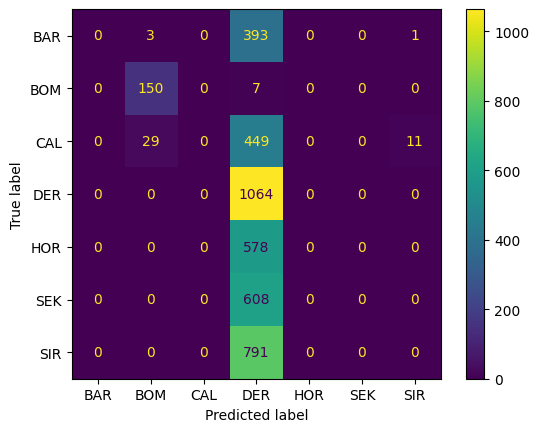

In [349]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, mlp_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

PCA MODELS

In [350]:
rf_clf3.fit(pca_X_train, pca_y_train)
dt_clf1.fit(pca_X_train, pca_y_train)
knn_clf2.fit(pca_X_train, pca_y_train)
nc_clf2.fit(pca_X_train, pca_y_train)
gb_clf1.fit(pca_X_train, pca_y_train)
rn_clf1.fit(pca_X_train, pca_y_train)
gnb_clf1.fit(pca_X_train, pca_y_train)
mlp_clf2.fit(pca_X_train, pca_y_train)

MLPClassifier(hidden_layer_sizes=(3,))

In [351]:
rf_clf3_train_y = rf_clf3.predict(pca_X_train)
rf_clf3_test_y = rf_clf3.predict(pca_X_test)

In [352]:
print(classification_report(pca_y_train, rf_clf3_train_y, target_names=rf_clf3.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.81      0.87       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.84      0.92      0.88      1141
    DERMASON       0.90      0.85      0.87      2482
       HOROZ       0.89      0.96      0.92      1350
       SEKER       0.87      0.95      0.91      1419
        SIRA       0.81      0.76      0.79      1845

    accuracy                           0.87      9527
   macro avg       0.89      0.89      0.89      9527
weighted avg       0.87      0.87      0.87      9527



In [353]:
print(classification_report(pca_y_test, rf_clf3_test_y, target_names=rf_clf3.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.82      0.88       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.85      0.92      0.88       489
    DERMASON       0.89      0.86      0.88      1064
       HOROZ       0.88      0.93      0.91       578
       SEKER       0.87      0.97      0.92       608
        SIRA       0.81      0.75      0.78       791

    accuracy                           0.87      4084
   macro avg       0.89      0.89      0.89      4084
weighted avg       0.88      0.87      0.87      4084



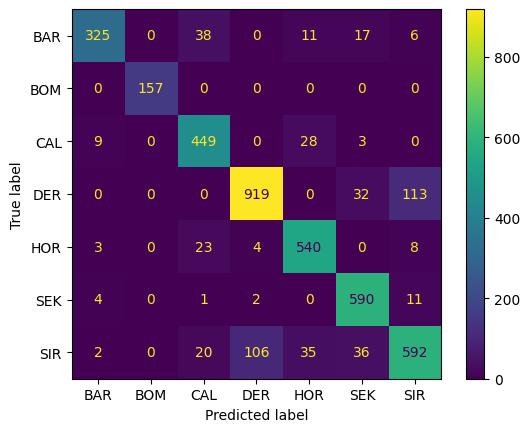

In [354]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, rf_clf3_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [355]:
dt_clf1_train_y = dt_clf1.predict(pca_X_train)
dt_clf1_test_y = dt_clf1.predict(pca_X_test)

In [356]:
print(classification_report(pca_y_train, dt_clf1_train_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.99      1.00      0.99       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.99      0.99      0.99      1141
    DERMASON       0.99      1.00      1.00      2482
       HOROZ       1.00      0.99      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      0.99      0.99      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [357]:
print(classification_report(pca_y_test, dt_clf1_test_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.86      0.88      0.87       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.88      0.90       489
    DERMASON       0.89      0.91      0.90      1064
       HOROZ       0.94      0.93      0.93       578
       SEKER       0.94      0.94      0.94       608
        SIRA       0.84      0.82      0.83       791

    accuracy                           0.90      4084
   macro avg       0.91      0.91      0.91      4084
weighted avg       0.90      0.90      0.90      4084



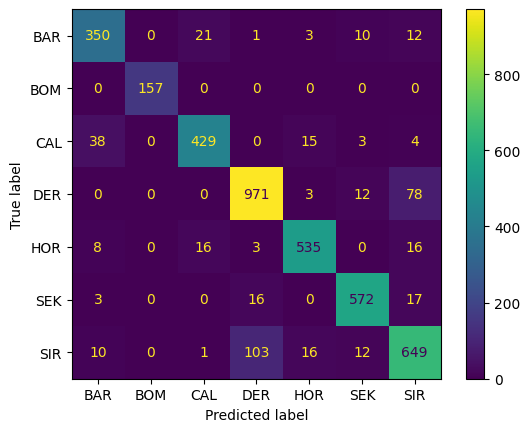

In [358]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, dt_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [359]:
knn_clf2_train_y = knn_clf2.predict(pca_X_train)
knn_clf2_test_y = knn_clf2.predict(pca_X_test)

In [360]:
print(classification_report(pca_y_train, knn_clf2_train_y, target_names=knn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [361]:
print(classification_report(pca_y_test, knn_clf2_test_y, target_names=knn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.89      0.92       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.94      0.93       489
    DERMASON       0.90      0.92      0.91      1064
       HOROZ       0.95      0.94      0.95       578
       SEKER       0.95      0.95      0.95       608
        SIRA       0.86      0.86      0.86       791

    accuracy                           0.92      4084
   macro avg       0.94      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



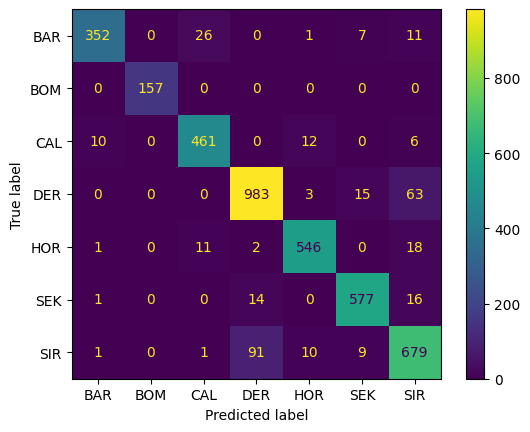

In [362]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, knn_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [363]:
nc_clf2_train_y = nc_clf2.predict(pca_X_train)
nc_clf2_test_y = nc_clf2.predict(pca_X_test)

In [364]:
print(classification_report(pca_y_train, nc_clf2_train_y, target_names=nc_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.82      0.87       925
      BOMBAY       1.00      0.99      1.00       365
        CALI       0.85      0.93      0.89      1141
    DERMASON       0.91      0.82      0.86      2482
       HOROZ       0.93      0.92      0.93      1350
       SEKER       0.91      0.91      0.91      1419
        SIRA       0.76      0.88      0.82      1845

    accuracy                           0.88      9527
   macro avg       0.90      0.90      0.90      9527
weighted avg       0.88      0.88      0.88      9527



In [365]:
print(classification_report(pca_y_test, nc_clf2_test_y, target_names=nc_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.79      0.86       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.84      0.93      0.88       489
    DERMASON       0.91      0.81      0.86      1064
       HOROZ       0.94      0.90      0.92       578
       SEKER       0.89      0.94      0.91       608
        SIRA       0.76      0.87      0.82       791

    accuracy                           0.87      4084
   macro avg       0.90      0.89      0.89      4084
weighted avg       0.88      0.87      0.88      4084



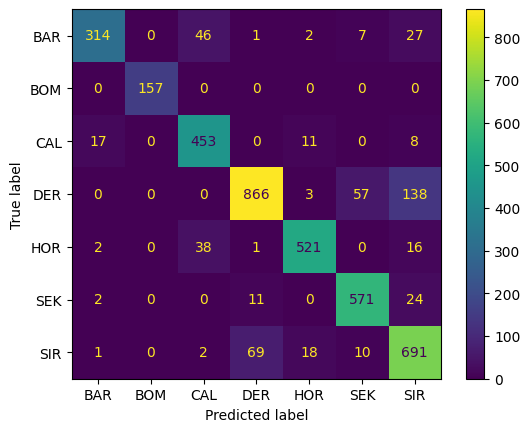

In [366]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, nc_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [367]:
gb_clf1_train_y = gb_clf1.predict(pca_X_train)
gb_clf1_test_y = gb_clf1.predict(pca_X_test)

In [368]:
print(classification_report(pca_y_train, gb_clf1_train_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.91      0.93       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.94      0.95      0.95      1141
    DERMASON       0.92      0.93      0.92      2482
       HOROZ       0.97      0.97      0.97      1350
       SEKER       0.95      0.95      0.95      1419
        SIRA       0.87      0.88      0.88      1845

    accuracy                           0.93      9527
   macro avg       0.94      0.94      0.94      9527
weighted avg       0.93      0.93      0.93      9527



In [369]:
print(classification_report(pca_y_test, gb_clf1_test_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.87      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.94      0.93       489
    DERMASON       0.91      0.92      0.91      1064
       HOROZ       0.96      0.94      0.95       578
       SEKER       0.95      0.96      0.95       608
        SIRA       0.84      0.85      0.84       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



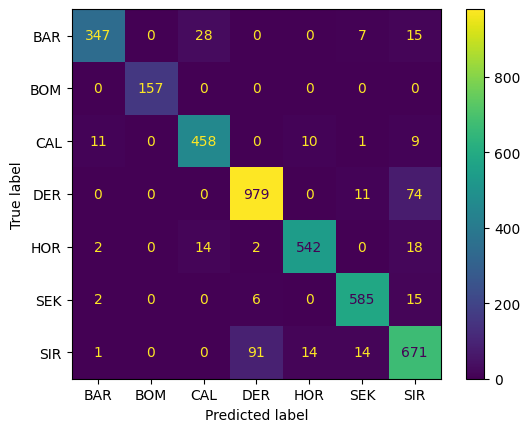

In [370]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, gb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [371]:
rn_clf1_train_y = rn_clf1.predict(pca_X_train)
rn_clf1_test_y = rn_clf1.predict(pca_X_test)

In [372]:
print(classification_report(pca_y_train, rn_clf1_train_y, target_names=rn_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [373]:
print(classification_report(pca_y_test, rn_clf1_test_y, target_names=rn_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.99      0.20      0.33       397
      BOMBAY       1.00      0.98      0.99       157
        CALI       0.80      0.86      0.83       489
    DERMASON       0.78      0.98      0.87      1064
       HOROZ       0.97      0.89      0.93       578
       SEKER       0.97      0.86      0.91       608
        SIRA       0.63      0.74      0.68       791

    accuracy                           0.81      4084
   macro avg       0.88      0.79      0.79      4084
weighted avg       0.84      0.81      0.79      4084



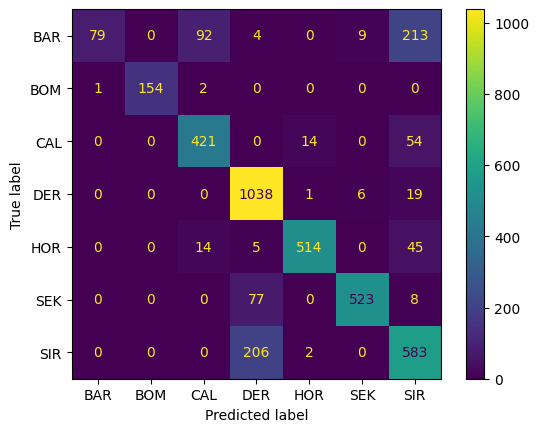

In [374]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, rn_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [375]:
gnb_clf1_train_y = gnb_clf1.predict(pca_X_train)
gnb_clf1_test_y = gnb_clf1.predict(pca_X_test)

In [376]:
print(classification_report(pca_y_train, gnb_clf1_train_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.85      0.89       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.90      0.95      0.93      1141
    DERMASON       0.94      0.82      0.87      2482
       HOROZ       0.94      0.96      0.95      1350
       SEKER       0.94      0.92      0.93      1419
        SIRA       0.76      0.89      0.82      1845

    accuracy                           0.89      9527
   macro avg       0.91      0.91      0.91      9527
weighted avg       0.90      0.89      0.89      9527



In [377]:
print(classification_report(pca_y_test, gnb_clf1_test_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.85      0.90       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.91      0.92      0.91       489
    DERMASON       0.94      0.82      0.88      1064
       HOROZ       0.92      0.94      0.93       578
       SEKER       0.94      0.95      0.94       608
        SIRA       0.75      0.89      0.82       791

    accuracy                           0.89      4084
   macro avg       0.92      0.91      0.91      4084
weighted avg       0.90      0.89      0.89      4084



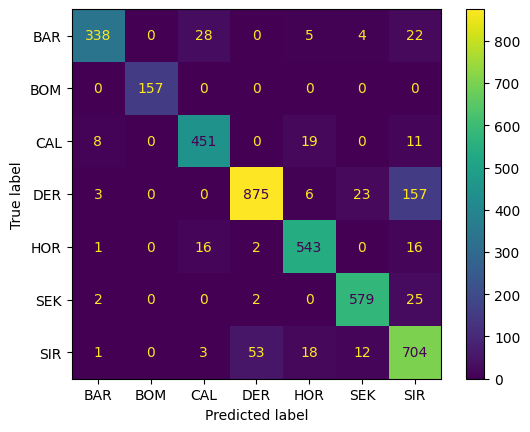

In [378]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, gnb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [379]:
mlp_clf2_train_y = mlp_clf2.predict(pca_X_train)
mlp_clf2_test_y = mlp_clf2.predict(pca_X_test)

In [380]:
print(classification_report(pca_y_train, mlp_clf2_train_y, target_names=mlp_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.71      0.01      0.02       925
      BOMBAY       0.00      0.00      0.00       365
        CALI       0.00      0.00      0.00      1141
    DERMASON       0.60      0.88      0.71      2482
       HOROZ       0.35      0.94      0.52      1350
       SEKER       0.69      0.15      0.25      1419
        SIRA       0.74      0.79      0.76      1845

    accuracy                           0.54      9527
   macro avg       0.44      0.40      0.32      9527
weighted avg       0.52      0.54      0.45      9527



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [381]:
print(classification_report(pca_y_test, mlp_clf2_test_y, target_names=mlp_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.56      0.01      0.02       397
      BOMBAY       0.00      0.00      0.00       157
        CALI       0.00      0.00      0.00       489
    DERMASON       0.59      0.87      0.71      1064
       HOROZ       0.36      0.95      0.53       578
       SEKER       0.65      0.16      0.26       608
        SIRA       0.74      0.79      0.76       791

    accuracy                           0.54      4084
   macro avg       0.41      0.40      0.33      4084
weighted avg       0.50      0.54      0.45      4084



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


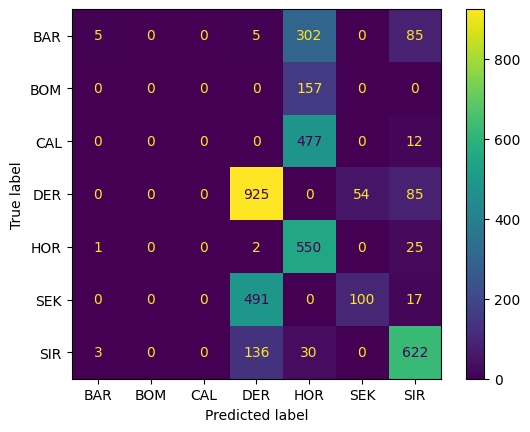

In [382]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, mlp_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

LDA MODELS

In [383]:
rf_clf4.fit(lda_X_train, lda_y_train)
dt_clf1.fit(lda_X_train, lda_y_train)
knn_clf2.fit(lda_X_train, lda_y_train)
nc_clf2.fit(lda_X_train, lda_y_train)
gb_clf1.fit(lda_X_train, lda_y_train)
rn_clf2.fit(lda_X_train, lda_y_train)
gnb_clf1.fit(lda_X_train, lda_y_train)
mlp_clf2.fit(lda_X_train, lda_y_train)

MLPClassifier(hidden_layer_sizes=(3,))

In [384]:
rf_clf4_train_y = rf_clf4.predict(lda_X_train)
rf_clf4_test_y = rf_clf4.predict(lda_X_test)

In [385]:
print(classification_report(lda_y_train, rf_clf4_train_y, target_names=rf_clf4.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.82      0.87       925
      BOMBAY       1.00      0.69      0.82       365
        CALI       0.86      0.96      0.91      1141
    DERMASON       0.85      0.94      0.89      2482
       HOROZ       0.94      0.94      0.94      1350
       SEKER       0.96      0.92      0.94      1419
        SIRA       0.86      0.83      0.84      1845

    accuracy                           0.89      9527
   macro avg       0.92      0.87      0.89      9527
weighted avg       0.90      0.89      0.89      9527



In [386]:
print(classification_report(lda_y_test, rf_clf4_test_y, target_names=rf_clf4.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.81      0.86       397
      BOMBAY       1.00      0.67      0.80       157
        CALI       0.85      0.94      0.89       489
    DERMASON       0.86      0.95      0.90      1064
       HOROZ       0.94      0.93      0.94       578
       SEKER       0.98      0.91      0.94       608
        SIRA       0.86      0.85      0.85       791

    accuracy                           0.89      4084
   macro avg       0.92      0.86      0.88      4084
weighted avg       0.90      0.89      0.89      4084



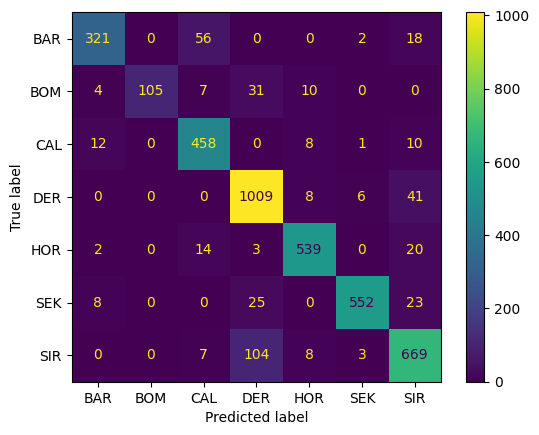

In [387]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, rf_clf4_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [388]:
dt_clf1_train_y = dt_clf1.predict(lda_X_train)
dt_clf1_test_y = dt_clf1.predict(lda_X_test)

In [389]:
print(classification_report(lda_y_train, dt_clf1_train_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.99      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       0.99      1.00      1.00      2482
       HOROZ       1.00      0.99      1.00      1350
       SEKER       0.99      1.00      1.00      1419
        SIRA       1.00      0.98      0.99      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [390]:
print(classification_report(lda_y_test, dt_clf1_test_y, target_names=dt_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.89      0.90      0.89       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.89      0.92      0.90       489
    DERMASON       0.90      0.90      0.90      1064
       HOROZ       0.95      0.93      0.94       578
       SEKER       0.93      0.93      0.93       608
        SIRA       0.84      0.83      0.83       791

    accuracy                           0.90      4084
   macro avg       0.91      0.91      0.91      4084
weighted avg       0.90      0.90      0.90      4084



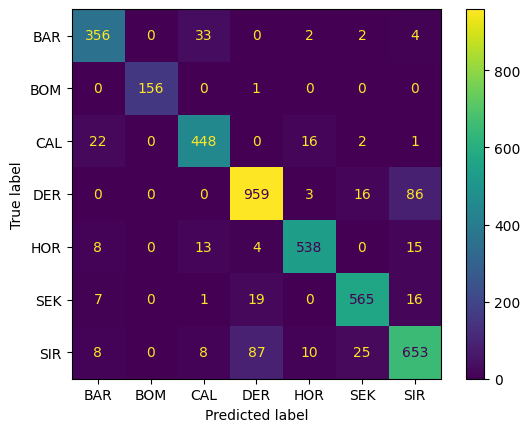

In [391]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, dt_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [392]:
knn_clf2_train_y = knn_clf2.predict(lda_X_train)
knn_clf2_test_y = knn_clf2.predict(lda_X_test)

In [393]:
print(classification_report(lda_y_train, knn_clf2_train_y, target_names=knn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [394]:
print(classification_report(lda_y_test, knn_clf2_test_y, target_names=knn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.94      0.93       489
    DERMASON       0.92      0.93      0.93      1064
       HOROZ       0.96      0.94      0.95       578
       SEKER       0.96      0.95      0.95       608
        SIRA       0.88      0.88      0.88       791

    accuracy                           0.93      4084
   macro avg       0.94      0.94      0.94      4084
weighted avg       0.93      0.93      0.93      4084



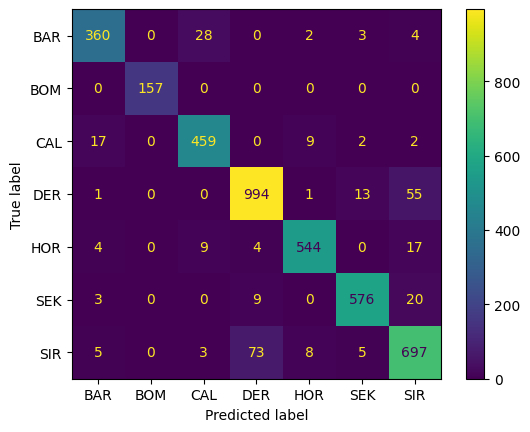

In [395]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, knn_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [396]:
nc_clf2_train_y = nc_clf2.predict(lda_X_train)
nc_clf2_test_y = nc_clf2.predict(lda_X_test)

In [397]:
print(classification_report(lda_y_train, nc_clf2_train_y, target_names=nc_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.86      0.91       925
      BOMBAY       1.00      0.99      1.00       365
        CALI       0.92      0.96      0.94      1141
    DERMASON       0.91      0.86      0.88      2482
       HOROZ       0.98      0.94      0.96      1350
       SEKER       0.96      0.90      0.93      1419
        SIRA       0.77      0.92      0.84      1845

    accuracy                           0.90      9527
   macro avg       0.93      0.92      0.92      9527
weighted avg       0.91      0.90      0.90      9527



In [398]:
print(classification_report(lda_y_test, nc_clf2_test_y, target_names=nc_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.85      0.90       397
      BOMBAY       1.00      0.99      0.99       157
        CALI       0.90      0.94      0.92       489
    DERMASON       0.94      0.88      0.91      1064
       HOROZ       0.97      0.93      0.95       578
       SEKER       0.97      0.90      0.93       608
        SIRA       0.78      0.94      0.85       791

    accuracy                           0.91      4084
   macro avg       0.93      0.92      0.92      4084
weighted avg       0.92      0.91      0.91      4084



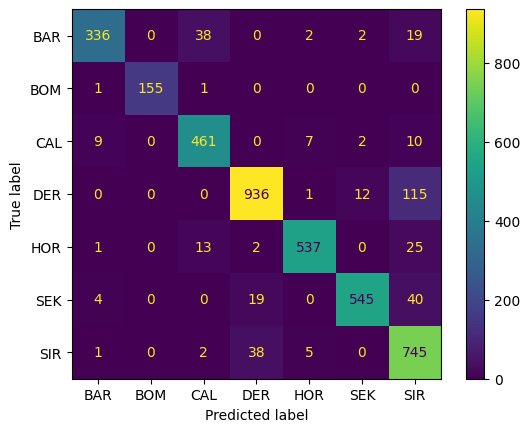

In [399]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, nc_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [400]:
gb_clf1_train_y = gb_clf1.predict(lda_X_train)
gb_clf1_test_y = gb_clf1.predict(lda_X_test)

In [401]:
print(classification_report(lda_y_train, gb_clf1_train_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.94      0.95       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.96      0.96      0.96      1141
    DERMASON       0.91      0.94      0.92      2482
       HOROZ       0.97      0.96      0.97      1350
       SEKER       0.97      0.94      0.95      1419
        SIRA       0.89      0.88      0.88      1845

    accuracy                           0.94      9527
   macro avg       0.95      0.94      0.95      9527
weighted avg       0.94      0.94      0.94      9527



In [402]:
print(classification_report(lda_y_test, gb_clf1_test_y, target_names=gb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.93      0.93      0.93       489
    DERMASON       0.91      0.95      0.93      1064
       HOROZ       0.96      0.94      0.95       578
       SEKER       0.97      0.93      0.95       608
        SIRA       0.87      0.87      0.87       791

    accuracy                           0.93      4084
   macro avg       0.94      0.93      0.94      4084
weighted avg       0.93      0.93      0.93      4084



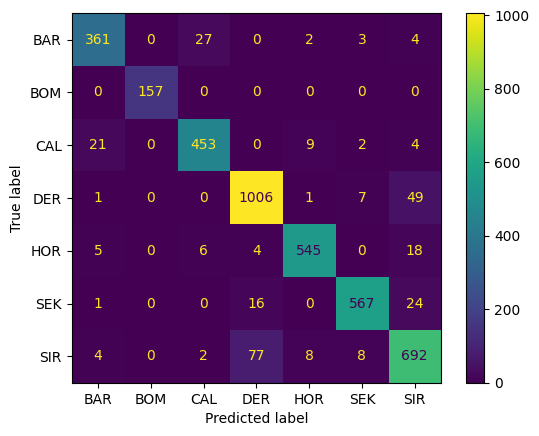

In [403]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, gb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [404]:
rn_clf2_train_y = rn_clf2.predict(lda_X_train)
rn_clf2_test_y = rn_clf2.predict(lda_X_test)

In [405]:
print(classification_report(lda_y_train, rn_clf2_train_y, target_names=rn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [406]:
print(classification_report(lda_y_test, rn_clf2_test_y, target_names=rn_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.97      0.83      0.90       397
      BOMBAY       1.00      0.97      0.99       157
        CALI       0.89      0.95      0.92       489
    DERMASON       0.93      0.92      0.93      1064
       HOROZ       0.97      0.94      0.96       578
       SEKER       0.97      0.92      0.94       608
        SIRA       0.82      0.92      0.87       791

    accuracy                           0.92      4084
   macro avg       0.94      0.92      0.93      4084
weighted avg       0.92      0.92      0.92      4084



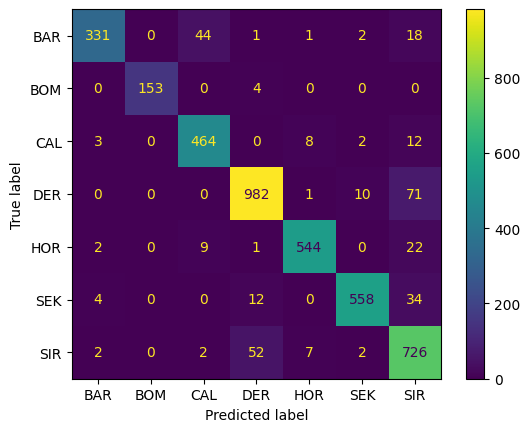

In [407]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, rn_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [408]:
gnb_clf1_train_y = gnb_clf1.predict(lda_X_train)
gnb_clf1_test_y = gnb_clf1.predict(lda_X_test)

In [409]:
print(classification_report(lda_y_train, gnb_clf1_train_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.91      0.90      0.90       925
      BOMBAY       0.99      1.00      1.00       365
        CALI       0.93      0.95      0.94      1141
    DERMASON       0.92      0.86      0.89      2482
       HOROZ       0.95      0.95      0.95      1350
       SEKER       0.94      0.92      0.93      1419
        SIRA       0.82      0.89      0.85      1845

    accuracy                           0.91      9527
   macro avg       0.92      0.93      0.92      9527
weighted avg       0.91      0.91      0.91      9527



In [410]:
print(classification_report(lda_y_test, gnb_clf1_test_y, target_names=gnb_clf1.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.90      0.90      0.90       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.94      0.93       489
    DERMASON       0.94      0.89      0.91      1064
       HOROZ       0.95      0.95      0.95       578
       SEKER       0.96      0.91      0.93       608
        SIRA       0.83      0.91      0.87       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



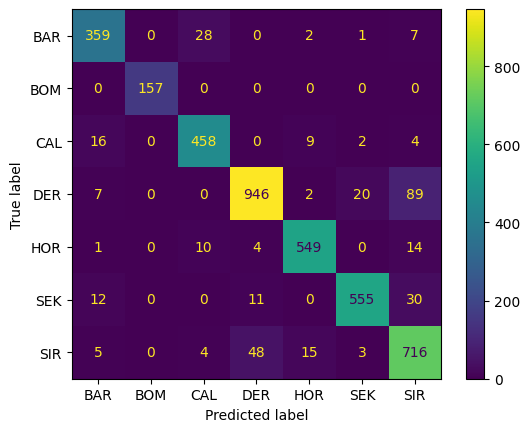

In [411]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, gnb_clf1_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [412]:
mlp_clf2_train_y = mlp_clf2.predict(lda_X_train)
mlp_clf2_test_y = mlp_clf2.predict(lda_X_test)

In [413]:
print(classification_report(lda_y_train, mlp_clf2_train_y, target_names=mlp_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.90      0.91       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.93      0.93      0.93      1141
    DERMASON       0.90      0.89      0.90      2482
       HOROZ       0.94      0.94      0.94      1350
       SEKER       0.95      0.93      0.94      1419
        SIRA       0.83      0.85      0.84      1845

    accuracy                           0.91      9527
   macro avg       0.92      0.92      0.92      9527
weighted avg       0.91      0.91      0.91      9527



In [414]:
print(classification_report(lda_y_test, mlp_clf2_test_y, target_names=mlp_clf2.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.91      0.89      0.90       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.91      0.93      0.92       489
    DERMASON       0.92      0.92      0.92      1064
       HOROZ       0.94      0.94      0.94       578
       SEKER       0.96      0.92      0.94       608
        SIRA       0.84      0.87      0.86       791

    accuracy                           0.91      4084
   macro avg       0.92      0.92      0.92      4084
weighted avg       0.91      0.91      0.91      4084



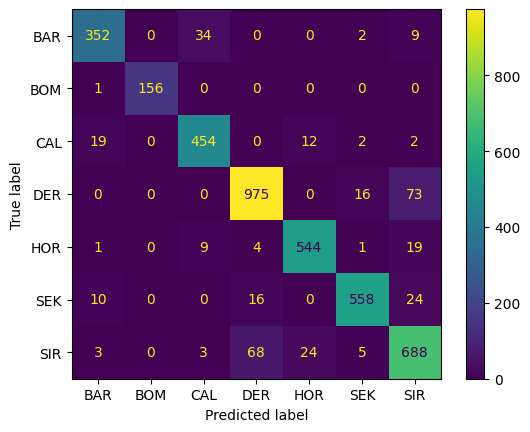

In [415]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, mlp_clf2_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

Ensemble Methods

In [416]:
base_X_train, base_X_test, base_y_train, base_y_test = train_test_split(features, target, test_size = 0.30, stratify=target)
pca_X_train, pca_X_test, pca_y_train, pca_y_test = train_test_split(pca_features, target, test_size = 0.30, stratify=target)
lda_X_train, lda_X_test, lda_y_train, lda_y_test = train_test_split(lda_features, target, test_size = 0.30, stratify=target)

In [417]:
base_models = ([("rf", rf_clf2),
                ("knn", knn_clf1),
                ("nc", nc_clf1),
                ("gb", gb_clf1),
                ("gnb", gnb_clf1)])

base_voting_model_soft = VotingClassifier(estimators=base_models, voting='soft')
base_voting_model_hard = VotingClassifier(estimators=base_models, voting='hard')

base_voting_model_stack_lr = StackingClassifier(estimators=base_models)

base_voting_model_soft.fit(base_X_train, base_y_train)
base_voting_model_hard.fit(base_X_train, base_y_train)
base_voting_model_stack_lr.fit(base_X_train, base_y_train)

base_soft_voting_train_y = base_voting_model_soft.predict(base_X_train)
base_soft_voting_test_y = base_voting_model_soft.predict(base_X_test)

base_hard_voting_train_y = base_voting_model_hard.predict(base_X_train)
base_hard_voting_test_y = base_voting_model_hard.predict(base_X_test)

base_stack_voting_train_y = base_voting_model_stack_lr.predict(base_X_train)
base_stack_voting_test_y = base_voting_model_stack_lr.predict(base_X_test)

In [418]:
print(classification_report(base_y_train, base_soft_voting_train_y, target_names=base_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.91      0.79      0.84       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.87      0.91      0.89      1141
    DERMASON       0.93      0.90      0.91      2482
       HOROZ       0.93      0.95      0.94      1350
       SEKER       0.95      0.94      0.94      1419
        SIRA       0.82      0.89      0.86      1845

    accuracy                           0.90      9527
   macro avg       0.92      0.91      0.91      9527
weighted avg       0.91      0.90      0.90      9527



In [419]:
print(classification_report(base_y_test, base_soft_voting_test_y, target_names=base_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.87      0.77      0.81       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.84      0.88      0.86       489
    DERMASON       0.92      0.89      0.91      1064
       HOROZ       0.93      0.94      0.93       578
       SEKER       0.97      0.91      0.94       608
        SIRA       0.80      0.89      0.84       791

    accuracy                           0.89      4084
   macro avg       0.90      0.90      0.90      4084
weighted avg       0.89      0.89      0.89      4084



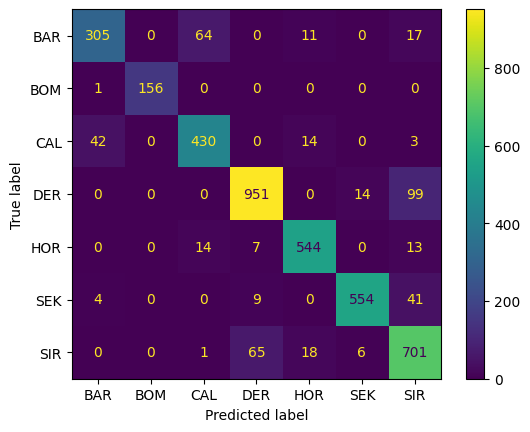

In [420]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, base_soft_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [421]:
print(classification_report(base_y_train, base_hard_voting_train_y, target_names=base_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.79      0.70      0.74       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.81      0.85      0.83      1141
    DERMASON       0.88      0.94      0.91      2482
       HOROZ       0.84      0.86      0.85      1350
       SEKER       0.88      0.84      0.86      1419
        SIRA       0.84      0.79      0.81      1845

    accuracy                           0.85      9527
   macro avg       0.86      0.86      0.86      9527
weighted avg       0.85      0.85      0.85      9527



In [422]:
print(classification_report(base_y_test, base_hard_voting_test_y, target_names=base_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.73      0.61      0.66       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.74      0.83      0.78       489
    DERMASON       0.86      0.92      0.89      1064
       HOROZ       0.82      0.84      0.83       578
       SEKER       0.85      0.78      0.81       608
        SIRA       0.81      0.78      0.79       791

    accuracy                           0.82      4084
   macro avg       0.83      0.82      0.82      4084
weighted avg       0.82      0.82      0.82      4084



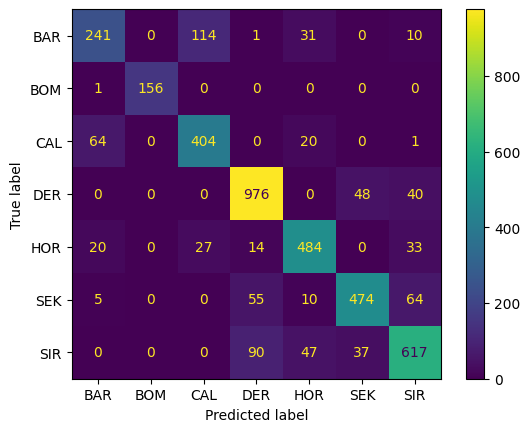

In [423]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, base_hard_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [424]:
print(classification_report(base_y_train, base_stack_voting_train_y, target_names=base_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.92      0.94       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.95      0.96      0.96      1141
    DERMASON       0.92      0.94      0.93      2482
       HOROZ       0.97      0.96      0.97      1350
       SEKER       0.97      0.95      0.96      1419
        SIRA       0.89      0.90      0.89      1845

    accuracy                           0.94      9527
   macro avg       0.95      0.95      0.95      9527
weighted avg       0.94      0.94      0.94      9527



In [425]:
print(classification_report(base_y_test, base_stack_voting_test_y, target_names=base_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.92      0.93       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.93      0.94      0.93       489
    DERMASON       0.91      0.92      0.91      1064
       HOROZ       0.97      0.94      0.96       578
       SEKER       0.97      0.93      0.95       608
        SIRA       0.85      0.88      0.86       791

    accuracy                           0.92      4084
   macro avg       0.94      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



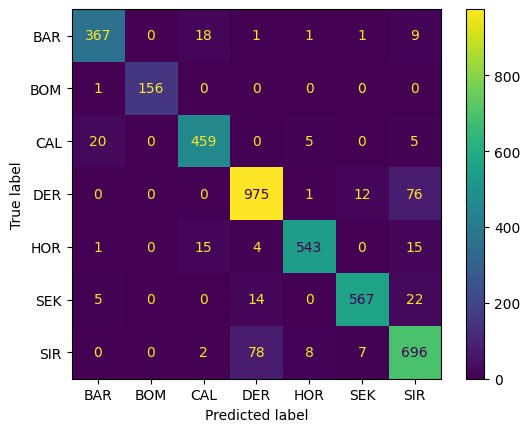

In [426]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(base_y_test, base_stack_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [427]:
pca_models = ([("rf", rf_clf3),
                ("knn", knn_clf2),
                ("gb", gb_clf1),
                ("rn", rn_clf1),
                ("gnb", gnb_clf1)])

pca_voting_model_soft = VotingClassifier(estimators=pca_models, voting='soft')
pca_voting_model_hard = VotingClassifier(estimators=pca_models, voting='hard')

pca_voting_model_stack_lr = StackingClassifier(estimators=pca_models)

pca_voting_model_soft.fit(pca_X_train, pca_y_train)
pca_voting_model_hard.fit(pca_X_train, pca_y_train)
pca_voting_model_stack_lr.fit(pca_X_train, pca_y_train)

pca_soft_voting_train_y = pca_voting_model_soft.predict(pca_X_train)
pca_soft_voting_test_y = pca_voting_model_soft.predict(pca_X_test)

pca_hard_voting_train_y = pca_voting_model_hard.predict(pca_X_train)
pca_hard_voting_test_y = pca_voting_model_hard.predict(pca_X_test)

pca_stack_voting_train_y = pca_voting_model_stack_lr.predict(pca_X_train)
pca_stack_voting_test_y = pca_voting_model_stack_lr.predict(pca_X_test)

In [428]:
print(classification_report(pca_y_train, pca_soft_voting_train_y, target_names=pca_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.99      0.98      0.99       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.99      0.99      0.99      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       0.99      0.99      0.99      1350
       SEKER       0.99      0.99      0.99      1419
        SIRA       0.99      0.99      0.99      1845

    accuracy                           0.99      9527
   macro avg       0.99      0.99      0.99      9527
weighted avg       0.99      0.99      0.99      9527



In [429]:
print(classification_report(pca_y_test, pca_soft_voting_test_y, target_names=pca_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.88      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.90      0.94      0.92       489
    DERMASON       0.93      0.91      0.92      1064
       HOROZ       0.96      0.93      0.94       578
       SEKER       0.96      0.95      0.95       608
        SIRA       0.84      0.89      0.86       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



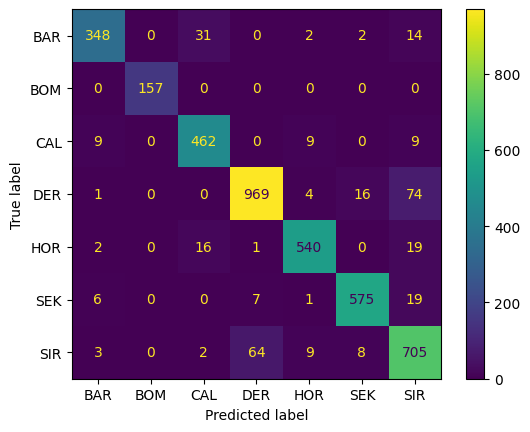

In [430]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, pca_soft_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [431]:
print(classification_report(pca_y_train, pca_hard_voting_train_y, target_names=pca_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.97      0.94      0.95       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.95      0.98      0.97      1141
    DERMASON       0.96      0.95      0.95      2482
       HOROZ       0.97      0.98      0.97      1350
       SEKER       0.96      0.97      0.97      1419
        SIRA       0.92      0.92      0.92      1845

    accuracy                           0.96      9527
   macro avg       0.96      0.96      0.96      9527
weighted avg       0.96      0.96      0.96      9527



In [432]:
print(classification_report(pca_y_test, pca_hard_voting_test_y, target_names=pca_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.87      0.90       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.91      0.94      0.93       489
    DERMASON       0.92      0.93      0.93      1064
       HOROZ       0.96      0.93      0.94       578
       SEKER       0.95      0.94      0.95       608
        SIRA       0.86      0.87      0.86       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



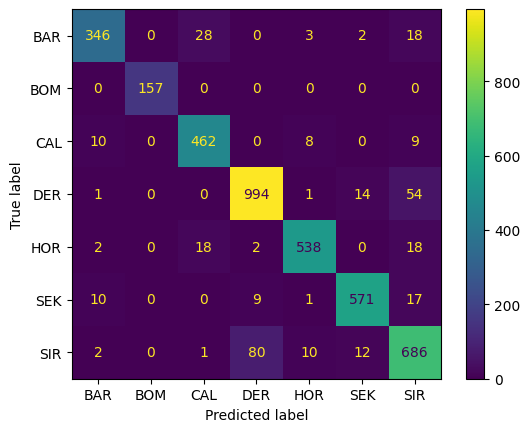

In [433]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, pca_hard_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [434]:
print(classification_report(pca_y_train, pca_stack_voting_train_y, target_names=pca_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [435]:
print(classification_report(pca_y_test, pca_stack_voting_test_y, target_names=pca_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.90      0.92       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.94      0.93       489
    DERMASON       0.92      0.94      0.93      1064
       HOROZ       0.97      0.93      0.95       578
       SEKER       0.96      0.95      0.95       608
        SIRA       0.86      0.88      0.87       791

    accuracy                           0.93      4084
   macro avg       0.94      0.93      0.94      4084
weighted avg       0.93      0.93      0.93      4084



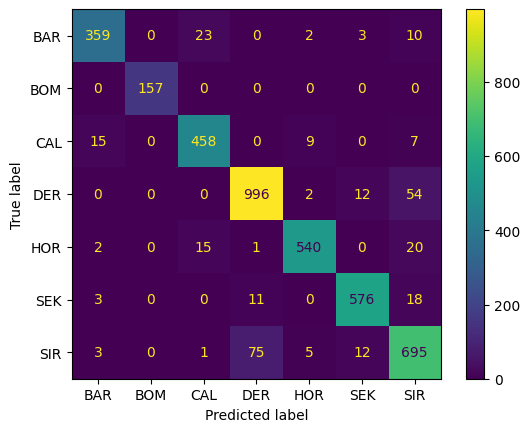

In [436]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(pca_y_test, pca_stack_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [437]:
lda_models = ([("rf", rf_clf4),
                ("knn", knn_clf2),
                ("gb", gb_clf1),
                ("rn", rn_clf2),
                ("gnb", gnb_clf1)])

lda_voting_model_soft = VotingClassifier(estimators=lda_models, voting='soft')
lda_voting_model_hard = VotingClassifier(estimators=lda_models, voting='hard')

lda_voting_model_stack_lr = StackingClassifier(estimators=lda_models)

lda_voting_model_soft.fit(lda_X_train, lda_y_train)
lda_voting_model_hard.fit(lda_X_train, lda_y_train)
lda_voting_model_stack_lr.fit(lda_X_train, lda_y_train)

lda_soft_voting_train_y = lda_voting_model_soft.predict(lda_X_train)
lda_soft_voting_test_y = lda_voting_model_soft.predict(lda_X_test)

lda_hard_voting_train_y = lda_voting_model_hard.predict(lda_X_train)
lda_hard_voting_test_y = lda_voting_model_hard.predict(lda_X_test)

lda_stack_voting_train_y = lda_voting_model_stack_lr.predict(lda_X_train)
lda_stack_voting_test_y = lda_voting_model_stack_lr.predict(lda_X_test)

In [438]:
print(classification_report(lda_y_train, lda_soft_voting_train_y, target_names=lda_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      0.98      0.99       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.99      0.99      0.99      1141
    DERMASON       0.97      0.98      0.98      2482
       HOROZ       0.99      0.98      0.99      1350
       SEKER       0.99      0.98      0.98      1419
        SIRA       0.96      0.97      0.96      1845

    accuracy                           0.98      9527
   macro avg       0.99      0.98      0.98      9527
weighted avg       0.98      0.98      0.98      9527



In [439]:
print(classification_report(lda_y_test, lda_soft_voting_test_y, target_names=lda_voting_model_soft.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.92       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.92      0.96      0.94       489
    DERMASON       0.92      0.91      0.91      1064
       HOROZ       0.96      0.95      0.96       578
       SEKER       0.97      0.92      0.95       608
        SIRA       0.83      0.88      0.86       791

    accuracy                           0.92      4084
   macro avg       0.94      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



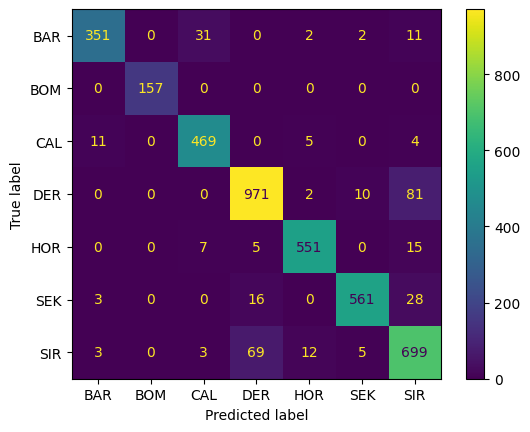

In [440]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, lda_soft_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [441]:
print(classification_report(lda_y_train, lda_hard_voting_train_y, target_names=lda_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.97      0.94      0.96       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       0.96      0.98      0.97      1141
    DERMASON       0.94      0.96      0.95      2482
       HOROZ       0.98      0.97      0.97      1350
       SEKER       0.97      0.96      0.96      1419
        SIRA       0.93      0.91      0.92      1845

    accuracy                           0.95      9527
   macro avg       0.96      0.96      0.96      9527
weighted avg       0.96      0.95      0.95      9527



In [442]:
print(classification_report(lda_y_test, lda_hard_voting_test_y, target_names=lda_voting_model_hard.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.96      0.87      0.91       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.91      0.96      0.93       489
    DERMASON       0.91      0.92      0.91      1064
       HOROZ       0.97      0.95      0.96       578
       SEKER       0.98      0.92      0.95       608
        SIRA       0.84      0.88      0.86       791

    accuracy                           0.92      4084
   macro avg       0.94      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



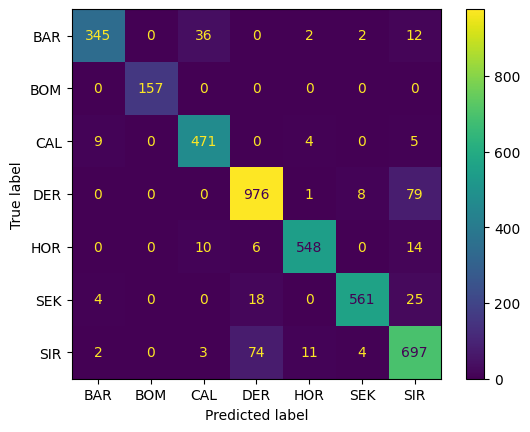

In [443]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, lda_hard_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()

In [444]:
print(classification_report(lda_y_train, lda_stack_voting_train_y, target_names=lda_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       1.00      1.00      1.00       925
      BOMBAY       1.00      1.00      1.00       365
        CALI       1.00      1.00      1.00      1141
    DERMASON       1.00      1.00      1.00      2482
       HOROZ       1.00      1.00      1.00      1350
       SEKER       1.00      1.00      1.00      1419
        SIRA       1.00      1.00      1.00      1845

    accuracy                           1.00      9527
   macro avg       1.00      1.00      1.00      9527
weighted avg       1.00      1.00      1.00      9527



In [445]:
print(classification_report(lda_y_test, lda_stack_voting_test_y, target_names=lda_voting_model_stack_lr.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.90      0.93       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.93      0.96      0.94       489
    DERMASON       0.91      0.93      0.92      1064
       HOROZ       0.97      0.95      0.96       578
       SEKER       0.97      0.94      0.96       608
        SIRA       0.86      0.87      0.87       791

    accuracy                           0.93      4084
   macro avg       0.94      0.94      0.94      4084
weighted avg       0.93      0.93      0.93      4084



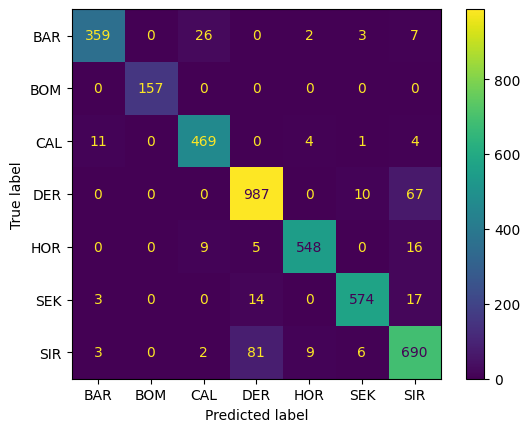

In [446]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(lda_y_test, lda_stack_voting_test_y), display_labels=["BAR", "BOM", "CAL", "DER", "HOR", "SEK", "SIR"])
disp.plot()